

1. Import Libraries
2. Dataset Loading
3. Exploratory Data Analysis
4. Image Preprocessing
5. Feature Extraction (HOG + GLCM)
6. Dataset Splitting
7. SVM Model
8. Random Forest Model
9. XGBoost Model
10. Model Comparison
11. Explainable AI & Heatmaps
12. Final Prediction System



In [ ]:

!wget -O brain-tumor-mri-dataset.zip "https://zenodo.org/records/12735702/files/brain-tumor-mri-dataset.zip?download=1"


--2026-11-22 19:00:36--  https://zenodo.org/records/12735702/files/brain-tumor-mri-dataset.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.47.192, 188.185.42.113, 188.185.51.60, ...
Connecting to zenodo.org (zenodo.org)|188.185.47.192|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 155791278 (149M) [application/octet-stream]
Saving to: ‘brain-tumor-mri-dataset.zip’

brain-tumor-mri-dat 100%[===================>] 148.57M  4.09MB/s    in 85s     

2026-11-22 19:02:02 (1.74 MB/s) - ‘brain-tumor-mri-dataset.zip’ saved [155791278/155791278]



In [ ]:

import zipfile
import os

zip_path = "/content/brain-tumor-mri-dataset.zip"
extract_path = "/content/brain_tumor_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [ ]:

for root, dirs, files in os.walk(extract_path):
    if "Training" in dirs and "Testing" in dirs:
        DATASET_PATH = root
        break

print("Dataset path:", DATASET_PATH)

print("\nTraining folders:")
print(os.listdir(os.path.join(DATASET_PATH, "Training")))

print("\nTesting folders:")
print(os.listdir(os.path.join(DATASET_PATH, "Testing")))


Dataset path: /content/brain_tumor_data

Training folders:
['notumor', 'meningioma', 'pituitary', 'glioma']

Testing folders:
['notumor', 'meningioma', 'pituitary', 'glioma']


In [ ]:

from collections import Counter

classes = ["glioma", "meningioma", "notumor", "pituitary"]

for folder in ["Training", "Testing"]:
    print("\n", folder)

    for category in classes:
        path = os.path.join(DATASET_PATH, folder, category)

        count = len([
            f for f in os.listdir(path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        print(category, ":", count)



 Training
glioma : 1321
meningioma : 1339
notumor : 1595
pituitary : 1457

 Testing
glioma : 300
meningioma : 306
notumor : 405
pituitary : 300


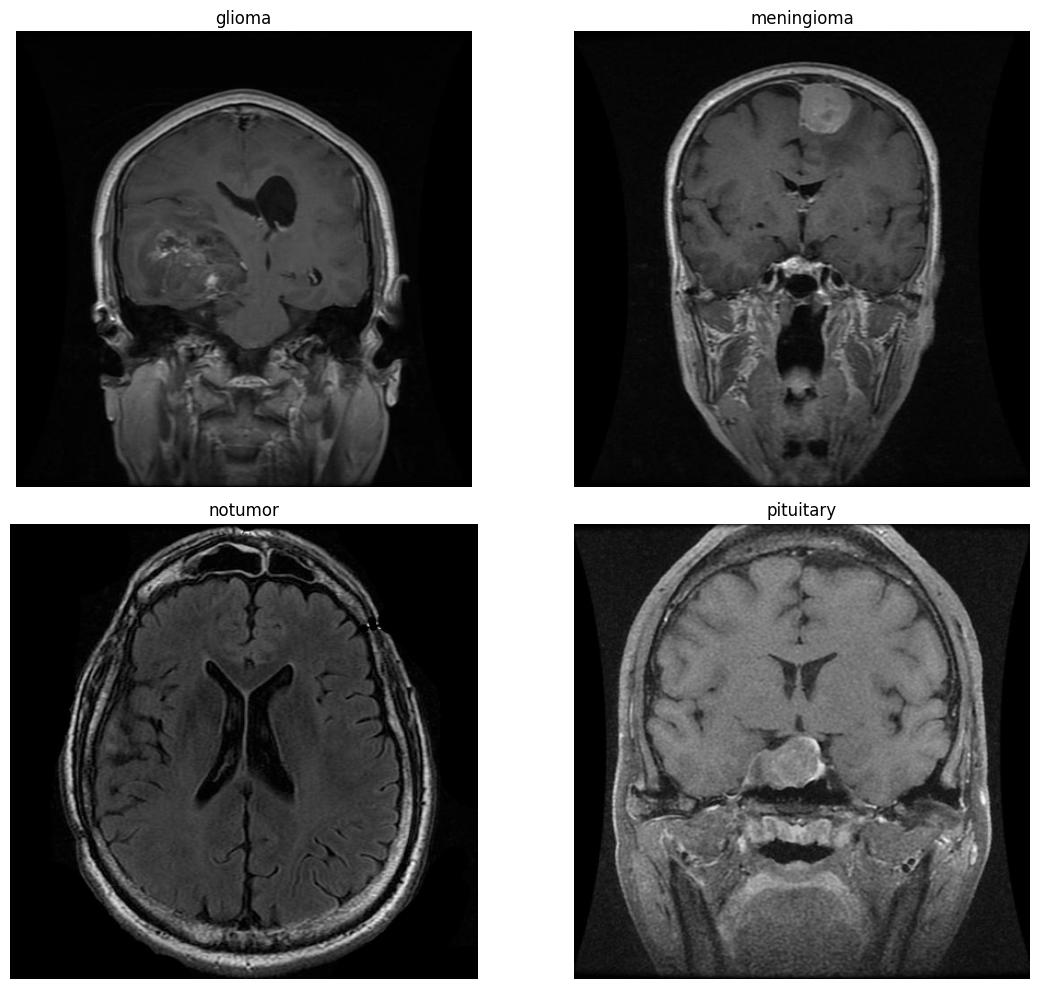

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
import glob

plt.figure(figsize=(12, 10))

for i, category in enumerate(classes):
    folder = os.path.join(
        DATASET_PATH, "Training", category
    )

    images = glob.glob(folder + "/*")

    img = Image.open(images[0])

    plt.subplot(2, 2, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(category)
    plt.axis("off")

plt.tight_layout()
plt.show()


glioma : 1321
meningioma : 1339
notumor : 1595
pituitary : 1457


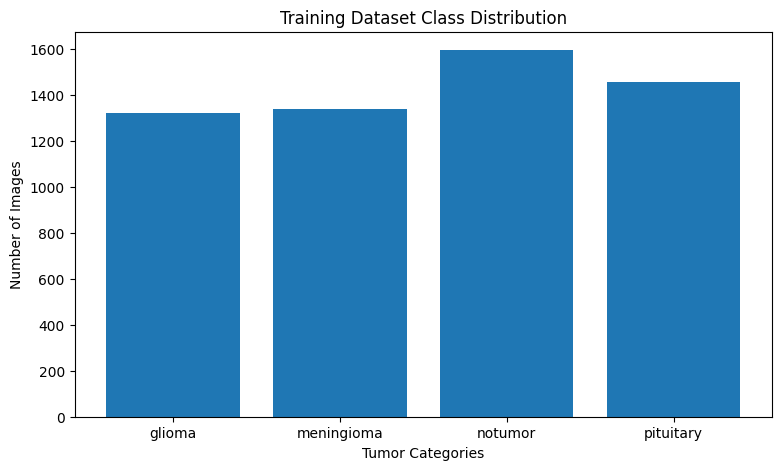

In [ ]:
import os
import matplotlib.pyplot as plt

classes = ["glioma", "meningioma", "notumor", "pituitary"]

train_counts = []

for category in classes:
    path = os.path.join(DATASET_PATH, "Training", category)

    count = len(os.listdir(path))
    train_counts.append(count)

    print(category, ":", count)

plt.figure(figsize=(9, 5))

plt.bar(classes, train_counts)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Tumor Categories")
plt.ylabel("Number of Images")

plt.show()

In [ ]:
import cv2
import glob

for category in classes:

    path = os.path.join(DATASET_PATH, "Training", category)

    image_path = glob.glob(path + "/*")[0]

    img = cv2.imread(image_path)

    print(category, ":", img.shape)

glioma : (512, 512, 3)
meningioma : (512, 512, 3)
notumor : (417, 428, 3)
pituitary : (512, 512, 3)


In [ ]:
for category in classes:

    path = os.path.join(DATASET_PATH, "Training", category)

    dimensions = []

    for file in os.listdir(path):

        img_path = os.path.join(path, file)

        img = cv2.imread(img_path)

        if img is not None:
            dimensions.append(img.shape[:2])

    print(category)
    print("Unique dimensions:", len(set(dimensions)))
    print("Sample dimensions:", dimensions[:5])
    print("------------------------")

glioma
Unique dimensions: 1
Sample dimensions: [(512, 512), (512, 512), (512, 512), (512, 512), (512, 512)]
------------------------
meningioma
Unique dimensions: 123
Sample dimensions: [(512, 512), (512, 512), (512, 512), (512, 512), (512, 512)]
------------------------
notumor
Unique dimensions: 254
Sample dimensions: [(417, 428), (442, 442), (231, 218), (225, 225), (225, 225)]
------------------------
pituitary
Unique dimensions: 16
Sample dimensions: [(512, 512), (512, 512), (512, 512), (512, 512), (512, 512)]
------------------------


In [ ]:
import cv2
import numpy as np

def preprocess_image(img_path):

    # Read image
    img = cv2.imread(img_path)

    if img is None:
        return None

    # Convert to grayscale
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Resize while preserving aspect ratio
    h, w = img.shape

    scale = min(224 / w, 224 / h)

    new_w = int(w * scale)
    new_h = int(h * scale)

    img = cv2.resize(img, (new_w, new_h))

    # Add padding
    canvas = np.zeros((224, 224), dtype=np.uint8)

    x = (224 - new_w) // 2
    y = (224 - new_h) // 2

    canvas[y:y+new_h, x:x+new_w] = img

    # Normalize
    img = canvas / 255.0

    return img

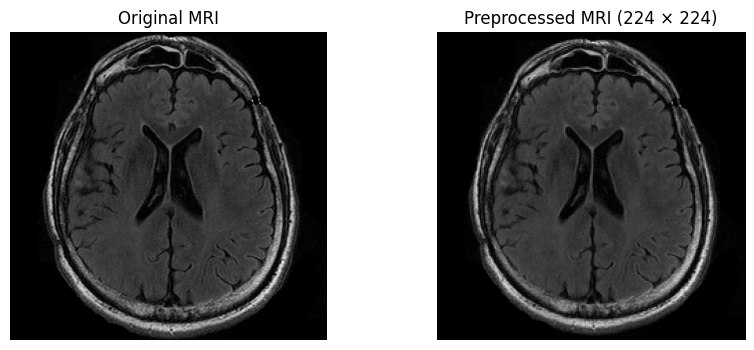

Processed shape: (224, 224)
Minimum pixel value: 0.0
Maximum pixel value: 0.9764705882352941


In [ ]:
import matplotlib.pyplot as plt
import os

category = "notumor"

folder = os.path.join(DATASET_PATH, "Training", category)

image_name = os.listdir(folder)[0]

image_path = os.path.join(folder, image_name)

processed_img = preprocess_image(image_path)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
original = cv2.imread(image_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
plt.imshow(original)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_img, cmap="gray")
plt.title("Preprocessed MRI (224 × 224)")
plt.axis("off")

plt.show()

print("Processed shape:", processed_img.shape)
print("Minimum pixel value:", processed_img.min())
print("Maximum pixel value:", processed_img.max())

In [ ]:
!pip install -q scikit-image

from skimage.feature import hog, graycomatrix, graycoprops
import numpy as np
import cv2

In [ ]:
def extract_features(img_path):

    # Preprocess image
    img = preprocess_image(img_path)

    # Convert normalized image to uint8
    img = (img * 255).astype(np.uint8)

    # ---------------- HOG FEATURES ----------------

    hog_features = hog(
        img,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        feature_vector=True
    )

    # ---------------- GLCM FEATURES ----------------

    glcm = graycomatrix(
        img,
        distances=[1, 2],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=256,
        symmetric=True,
        normed=True
    )

    properties = [
        'contrast',
        'dissimilarity',
        'homogeneity',
        'energy',
        'correlation',
        'ASM'
    ]

    glcm_features = []

    for prop in properties:

        values = graycoprops(glcm, prop)

        glcm_features.append(values.mean())
        glcm_features.append(values.std())

    # Combine both features
    features = np.concatenate([
        hog_features,
        glcm_features
    ])

    return features

In [ ]:
import os

category = "glioma"

folder = os.path.join(
    DATASET_PATH, "Training", category
)

image_name = os.listdir(folder)[0]

image_path = os.path.join(folder, image_name)

features = extract_features(image_path)

print("Feature extraction successful!")
print("Total features:", len(features))

print("\nFirst 10 features:")
print(features[:10])

Feature extraction successful!
Total features: 6096

First 10 features:
[0.30946697 0.07280931 0.09209729 0.07280931 0.30946697 0.
 0.30808182 0.25388536 0.08966623 0.30946697]


In [ ]:

import os
import numpy as np
from tqdm import tqdm

classes = ["glioma", "meningioma", "notumor", "pituitary"]

def extract_dataset_features(folder_path):

    X = []
    y = []

    for label, category in enumerate(classes):

        category_path = os.path.join(folder_path, category)

        for image_name in tqdm(os.listdir(category_path), desc=category):

            image_path = os.path.join(category_path, image_name)

            if not image_name.lower().endswith((".jpg", ".jpeg", ".png")):
                continue

            features = extract_features(image_path)

            if features is not None:
                X.append(features)
                y.append(label)

    X = np.array(X, dtype=np.float32)
    y = np.array(y)

    return X, y


# Extract training features
train_path = os.path.join(DATASET_PATH, "Training")

X_train, y_train = extract_dataset_features(train_path)

# Extract testing features
test_path = os.path.join(DATASET_PATH, "Testing")

X_test, y_test = extract_dataset_features(test_path)

print("\nFeature extraction completed!")

print("Training feature shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing feature shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)


pituitary: 100%|██████████| 300/300 [00:24<00:00, 12.13it/s]


Feature extraction completed!
Training feature shape: (5712, 6096)
Training labels shape: (5712,)
Testing feature shape: (1311, 6096)
Testing labels shape: (1311,)


In [ ]:
class_mapping = {
    0: "glioma",
    1: "meningioma",
    2: "notumor",
    3: "pituitary"
}

print(class_mapping)

{0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}


In [ ]:
from sklearn.model_selection import train_test_split

X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train_split.shape)
print("Validation data:", X_val.shape)

print("Training labels:", y_train_split.shape)
print("Validation labels:", y_val.shape)

Training data: (4569, 6096)
Validation data: (1143, 6096)
Training labels: (4569,)
Validation labels: (1143,)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_split)

X_val_scaled = scaler.transform(X_val)

print("Training scaled shape:", X_train_scaled.shape)
print("Validation scaled shape:", X_val_scaled.shape)

Training scaled shape: (4569, 6096)
Validation scaled shape: (1143, 6096)


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

svm_model.fit(X_train_scaled, y_train_split)

print("SVM training completed!")

SVM training completed!


In [ ]:
y_pred = svm_model.predict(X_val_scaled)

accuracy = accuracy_score(y_val, y_pred)

print("SVM Validation Accuracy:", accuracy * 100)

print("\nClassification Report:")

print(classification_report(
    y_val,
    y_pred,
    target_names=classes
))

SVM Validation Accuracy: 92.6509186351706

Classification Report:
              precision    recall  f1-score   support

      glioma       0.97      0.90      0.93       264
  meningioma       0.85      0.84      0.85       268
     notumor       0.94      0.97      0.96       319
   pituitary       0.94      0.98      0.96       292

    accuracy                           0.93      1143
   macro avg       0.93      0.92      0.92      1143
weighted avg       0.93      0.93      0.93      1143



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train using original features (no scaling required)
rf_model.fit(X_train_split, y_train_split)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_rf = rf_model.predict(X_val)

rf_accuracy = accuracy_score(y_val, y_pred_rf)

print("Random Forest Validation Accuracy:",
      rf_accuracy * 100)

print("\nClassification Report:")

print(classification_report(
    y_val,
    y_pred_rf,
    target_names=classes
))

Random Forest Validation Accuracy: 90.37620297462817

Classification Report:
              precision    recall  f1-score   support

      glioma       0.95      0.85      0.90       264
  meningioma       0.84      0.80      0.82       268
     notumor       0.92      0.98      0.95       319
   pituitary       0.91      0.97      0.94       292

    accuracy                           0.90      1143
   macro avg       0.90      0.90      0.90      1143
weighted avg       0.90      0.90      0.90      1143



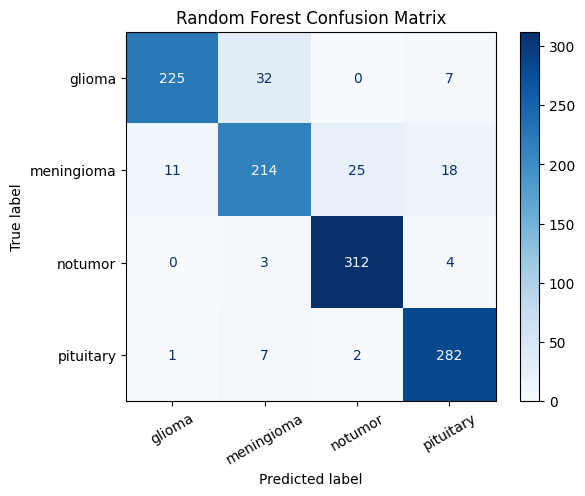

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Random Forest Confusion Matrix")
plt.xticks(rotation=30)
plt.show()

In [ ]:
!pip install -q xgboost

In [31]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=50,
    max_depth=3,
    learning_rate=0.1,
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    tree_method='hist',
    max_bin=64,
    subsample=0.8,
    colsample_bytree=0.5,
    random_state=42,
    n_jobs=2
)

xgb_model.fit(X_train_split, y_train_split)

print("XGBoost training completed!")

XGBoost training completed!


In [32]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_xgb = xgb_model.predict(X_val)

xgb_accuracy = accuracy_score(y_val, y_pred_xgb)

print("XGBoost Validation Accuracy:",
      xgb_accuracy * 100)

print("\nClassification Report:")

print(classification_report(
    y_val,
    y_pred_xgb,
    target_names=classes
))

XGBoost Validation Accuracy: 89.23884514435696

Classification Report:
              precision    recall  f1-score   support

      glioma       0.93      0.84      0.88       264
  meningioma       0.82      0.78      0.80       268
     notumor       0.92      0.97      0.95       319
   pituitary       0.89      0.96      0.92       292

    accuracy                           0.89      1143
   macro avg       0.89      0.89      0.89      1143
weighted avg       0.89      0.89      0.89      1143



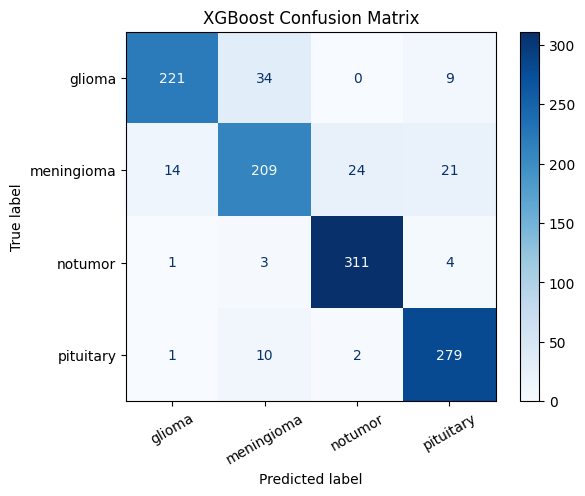

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_xgb = confusion_matrix(y_val, y_pred_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=classes
)

disp.plot(cmap="Blues", values_format="d")

plt.title("XGBoost Confusion Matrix")
plt.xticks(rotation=30)
plt.show()

In [34]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "SVM",
        "Random Forest",
        "XGBoost"
    ],
    "Validation Accuracy (%)": [
        92.65,
        90.38,
        89.24
    ]
})

results = results.sort_values(
    by="Validation Accuracy (%)",
    ascending=False
)

print(results)


           Model  Validation Accuracy (%)
0            SVM                    92.65
1  Random Forest                    90.38
2        XGBoost                    89.24


In [35]:
import numpy as np
import cv2
from skimage.feature import hog, graycomatrix, graycoprops

def extract_features_from_gray(img):

    hog_features = hog(
        img,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        feature_vector=True
    )

    glcm = graycomatrix(
        img,
        distances=[1, 2],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=256,
        symmetric=True,
        normed=True
    )

    properties = [
        'contrast',
        'dissimilarity',
        'homogeneity',
        'energy',
        'correlation',
        'ASM'
    ]

    glcm_features = []

    for prop in properties:
        values = graycoprops(glcm, prop)
        glcm_features.append(values.mean())
        glcm_features.append(values.std())

    return np.concatenate([
        hog_features,
        glcm_features
    ])


def get_prediction_scores(img):

    # Extract features
    features = extract_features_from_gray(img)

    # Scale features
    features = scaler.transform(
        features.reshape(1, -1)
    )

    # Get SVM decision scores
    scores = svm_model.decision_function(features)

    # Convert scores into normalized relative scores
    scores = scores - np.max(scores)
    exp_scores = np.exp(scores)

    normalized_scores = (
        exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
    )

    return normalized_scores[0]

In [36]:
# Select one MRI image
category = "glioma"

folder = os.path.join(
    DATASET_PATH, "Training", category
)

image_name = os.listdir(folder)[0]

image_path = os.path.join(folder, image_name)

# Preprocess image
processed_img = preprocess_image(image_path)

# Convert to uint8
processed_img_uint8 = (
    processed_img * 255
).astype(np.uint8)

# Get prediction scores
scores = get_prediction_scores(processed_img_uint8)

predicted_label = np.argmax(scores)

print("Predicted Class:", classes[predicted_label])

print("\nClass Scores:")

for i, class_name in enumerate(classes):
    print(class_name, ":", round(float(scores[i]), 4))

Predicted Class: glioma

Class Scores:
glioma : 0.6743
meningioma : 0.2488
notumor : 0.0207
pituitary : 0.0562


In [37]:
!pip install -q lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [38]:
from lime import lime_image

def lime_predict(images):

    predictions = []

    for image in images:

        # Convert RGB to grayscale
        gray = cv2.cvtColor(
            image.astype(np.uint8),
            cv2.COLOR_RGB2GRAY
        )

        # Get normalized SVM scores
        scores = get_prediction_scores(gray)

        predictions.append(scores)

    return np.array(predictions)

  0%|          | 0/100 [00:00<?, ?it/s]

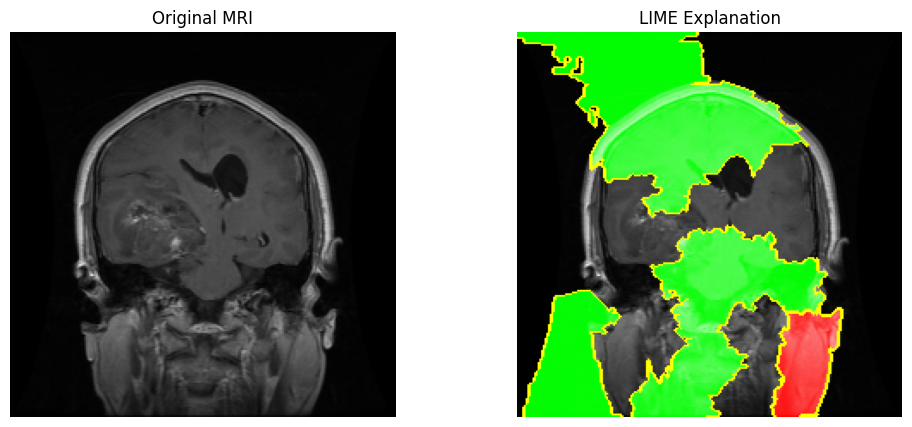

In [39]:
from skimage.segmentation import mark_boundaries
import matplotlib.pyplot as plt

# Convert MRI into RGB
rgb_image = np.stack(
    [processed_img_uint8] * 3,
    axis=-1
)

# Create LIME explainer
explainer = lime_image.LimeImageExplainer()

# Generate explanation
explanation = explainer.explain_instance(
    rgb_image,
    lime_predict,
    top_labels=4,
    hide_color=0,
    num_samples=100
)

# Explain predicted class
temp, mask = explanation.get_image_and_mask(
    label=predicted_label,
    positive_only=False,
    num_features=10,
    hide_rest=False
)

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(temp, mask))
plt.title("LIME Explanation")
plt.axis("off")

plt.show()

In [41]:
def generate_occlusion_heatmap(img, predicted_label):

    img = img.copy()

    # Original prediction score
    original_scores = get_prediction_scores(img)

    original_score = original_scores[predicted_label]

    heatmap = np.zeros(img.shape, dtype=np.float32)

    patch_size = 32
    stride = 32

    # Mean intensity used to hide image regions
    replacement = int(np.mean(img))

    for y in range(0, img.shape[0], stride):

        for x in range(0, img.shape[1], stride):

            # Copy original image
            occluded_img = img.copy()

            # Define patch boundaries
            y_end = min(y + patch_size, img.shape[0])
            x_end = min(x + patch_size, img.shape[1])

            # Replace patch
            occluded_img[y:y_end, x:x_end] = replacement

            # Get new prediction
            new_scores = get_prediction_scores(occluded_img)

            new_score = new_scores[predicted_label]

            # Calculate score reduction
            score_difference = original_score - new_score

            heatmap[y:y_end, x:x_end] = score_difference

    return heatmap

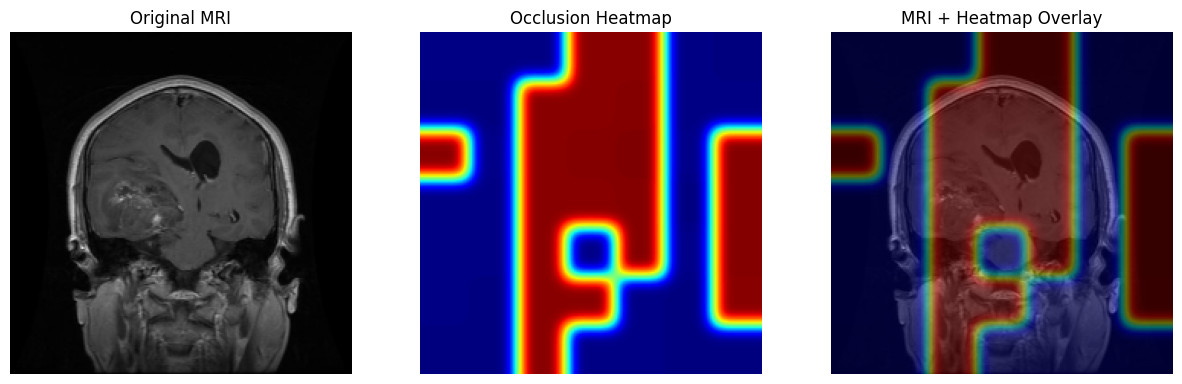

In [42]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

heatmap = generate_occlusion_heatmap(
    processed_img_uint8,
    predicted_label
)

# Normalize heatmap for visualization
heatmap_norm = cv2.normalize(
    heatmap,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Smooth heatmap
heatmap_smooth = cv2.GaussianBlur(
    heatmap_norm,
    (31, 31),
    0
)

# Apply color map
colored_heatmap = cv2.applyColorMap(
    heatmap_smooth,
    cv2.COLORMAP_JET
)

# Convert BGR to RGB
colored_heatmap = cv2.cvtColor(
    colored_heatmap,
    cv2.COLOR_BGR2RGB
)

# Convert original MRI to RGB
original_rgb = cv2.cvtColor(
    processed_img_uint8,
    cv2.COLOR_GRAY2RGB
)

# Overlay heatmap
overlay = cv2.addWeighted(
    original_rgb,
    0.6,
    colored_heatmap,
    0.4,
    0
)

# Display
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_smooth, cmap="jet")
plt.title("Occlusion Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("MRI + Heatmap Overlay")
plt.axis("off")

plt.show()

In [43]:

def generate_occlusion_heatmap(img, predicted_label):

    img = img.copy()

    original_scores = get_prediction_scores(img)
    original_score = original_scores[predicted_label]

    heatmap = np.zeros(img.shape, dtype=np.float32)
    counts = np.zeros(img.shape, dtype=np.float32)

    patch_size = 32
    stride = 8

    replacement = int(np.mean(img))

    for y in range(0, img.shape[0] - patch_size + 1, stride):

        for x in range(0, img.shape[1] - patch_size + 1, stride):

            occluded_img = img.copy()

            # Hide the selected patch
            occluded_img[
                y:y+patch_size,
                x:x+patch_size
            ] = replacement

            new_scores = get_prediction_scores(occluded_img)

            score_difference = (
                original_score - new_scores[predicted_label]
            )

            # Accumulate overlapping patch contributions
            heatmap[
                y:y+patch_size,
                x:x+patch_size
            ] += score_difference

            counts[
                y:y+patch_size,
                x:x+patch_size
            ] += 1

    # Average overlapping contributions
    heatmap = heatmap / np.maximum(counts, 1)

    return heatmap


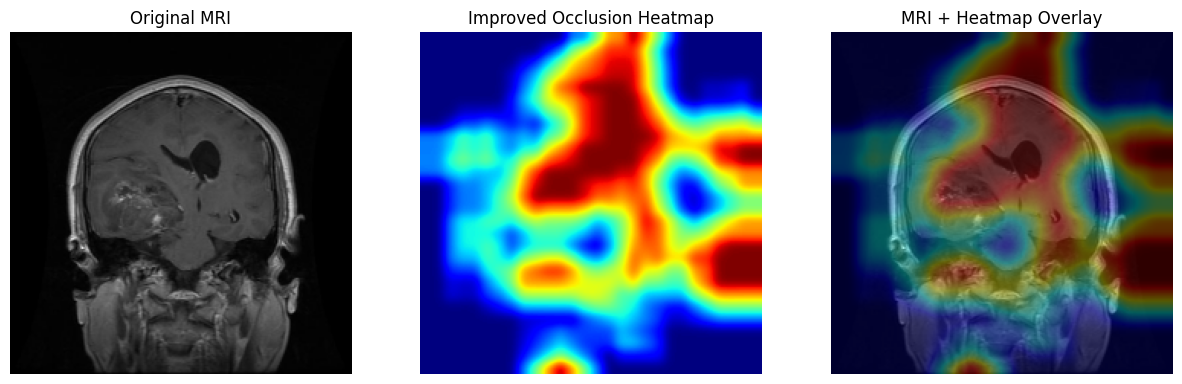

In [44]:

heatmap = generate_occlusion_heatmap(
    processed_img_uint8,
    predicted_label
)

# Display only positive score reductions
positive_heatmap = np.maximum(heatmap, 0)

# Normalize
heatmap_norm = cv2.normalize(
    positive_heatmap,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Smooth
heatmap_smooth = cv2.GaussianBlur(
    heatmap_norm,
    (21, 21),
    0
)

# Apply color map
colored_heatmap = cv2.applyColorMap(
    heatmap_smooth,
    cv2.COLORMAP_JET
)

colored_heatmap = cv2.cvtColor(
    colored_heatmap,
    cv2.COLOR_BGR2RGB
)

original_rgb = cv2.cvtColor(
    processed_img_uint8,
    cv2.COLOR_GRAY2RGB
)

overlay = cv2.addWeighted(
    original_rgb,
    0.65,
    colored_heatmap,
    0.35,
    0
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_smooth, cmap="jet")
plt.title("Improved Occlusion Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("MRI + Heatmap Overlay")
plt.axis("off")

plt.show()


  0%|          | 0/1000 [00:00<?, ?it/s]

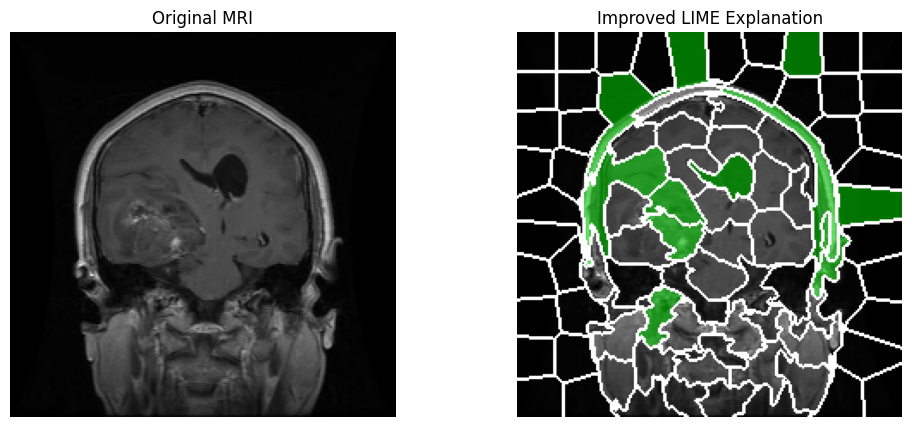

In [45]:
from skimage.segmentation import slic, mark_boundaries
import matplotlib.pyplot as plt
import numpy as np

# Use more detailed superpixel segmentation
def segmentation_fn(image):
    return slic(
        image,
        n_segments=100,
        compactness=10,
        sigma=1,
        start_label=0,
        channel_axis=-1
    )

# Generate improved explanation
explanation = explainer.explain_instance(
    rgb_image,
    lime_predict,
    top_labels=4,
    hide_color=0,
    num_samples=1000,
    segmentation_fn=segmentation_fn,
    random_seed=42
)

# Get contributions for predicted class
local_exp = explanation.local_exp[predicted_label]

# Select 10 strongest contributions
top_features = sorted(
    local_exp,
    key=lambda x: abs(x[1]),
    reverse=True
)[:10]

# Create visualization
overlay = rgb_image.astype(np.float32) / 255.0

for segment_id, weight in top_features:

    region = explanation.segments == segment_id

    if weight > 0:
        color = np.array([0, 1, 0])  # Green: supports prediction
    else:
        color = np.array([1, 0, 0])  # Red: opposes prediction

    overlay[region] = (
        0.55 * overlay[region] + 0.45 * color
    )

# Draw superpixel boundaries
result = mark_boundaries(
    overlay,
    explanation.segments,
    color=(1, 1, 1),
    mode="thick"
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result)
plt.title("Improved LIME Explanation")
plt.axis("off")

plt.show()

In [46]:
!pip install -q shap

In [47]:
import shap
import numpy as np

# Create SHAP explainer
explainer_rf = shap.TreeExplainer(rf_model)

# Use a small validation sample to control memory and runtime
X_shap = X_val[:30]

# Calculate SHAP values
shap_values = explainer_rf.shap_values(X_shap)

print("SHAP calculation completed!")

SHAP calculation completed!


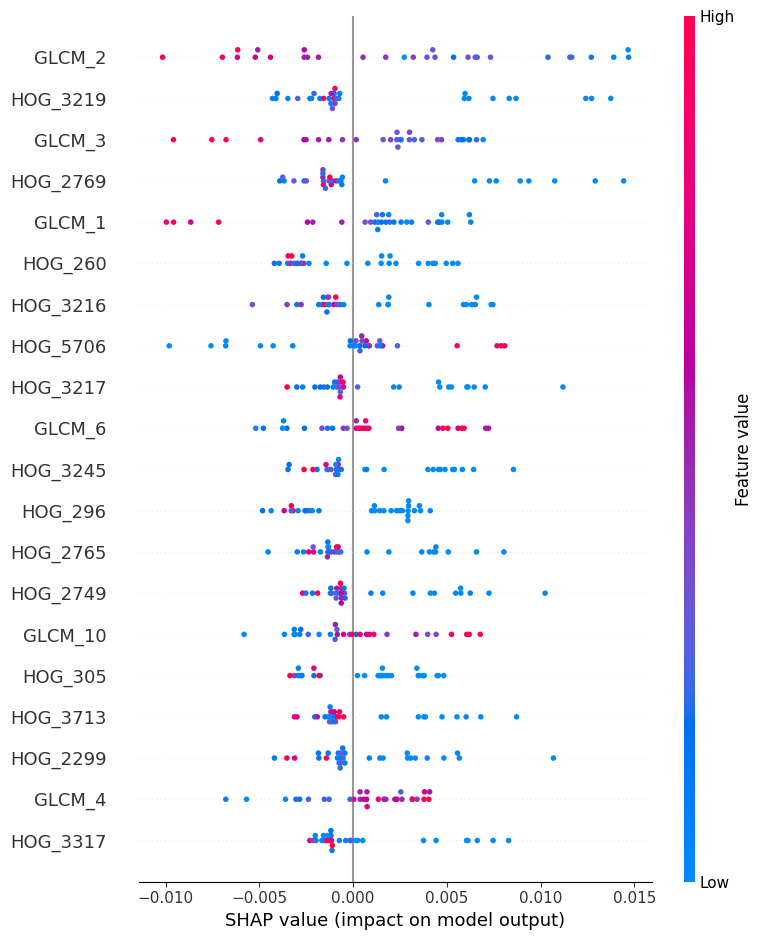

In [48]:
# Handle different SHAP output formats
if isinstance(shap_values, list):
    class_shap = shap_values[0]
else:
    class_shap = shap_values[:, :, 0]

# Generate feature names
feature_names = (
    [f"HOG_{i}" for i in range(6084)] +
    [f"GLCM_{i}" for i in range(12)]
)

shap.summary_plot(
    class_shap,
    X_shap,
    feature_names=feature_names,
    max_display=20
)

In [49]:
# Calculate mean absolute SHAP importance
mean_importance = np.mean(
    np.abs(class_shap),
    axis=0
)

hog_importance = np.sum(mean_importance[:6084])
glcm_importance = np.sum(mean_importance[6084:])

total_importance = hog_importance + glcm_importance

print("HOG importance:",
      round(hog_importance / total_importance * 100, 2), "%")

print("GLCM importance:",
      round(glcm_importance / total_importance * 100, 2), "%")

HOG importance: 96.02 %
GLCM importance: 3.98 %


Feature Family  Number of Features  Total Importance  Average Importance per Feature
           HOG                6084           0.64492                        0.000106
          GLCM                  12           0.02671                        0.002226


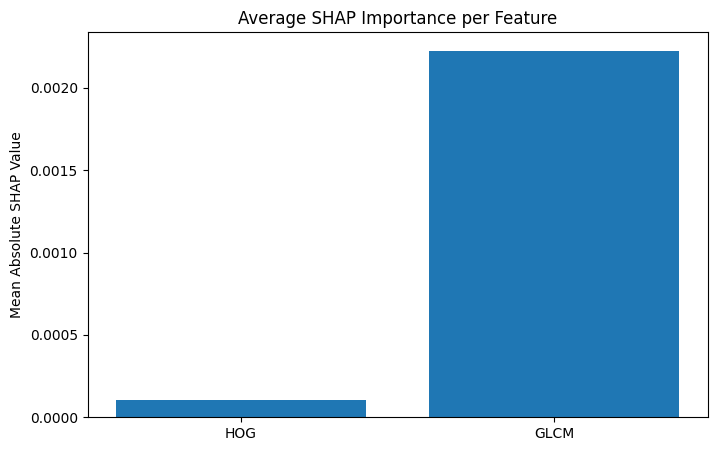

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mean_importance = np.mean(
    np.abs(class_shap),
    axis=0
)

hog_values = mean_importance[:6084]
glcm_values = mean_importance[6084:]

comparison = pd.DataFrame({
    "Feature Family": ["HOG", "GLCM"],
    "Number of Features": [6084, 12],
    "Total Importance": [
        np.sum(hog_values),
        np.sum(glcm_values)
    ],
    "Average Importance per Feature": [
        np.mean(hog_values),
        np.mean(glcm_values)
    ]
})

print(comparison.to_string(index=False))

# Compare average importance per feature
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Feature Family"],
    comparison["Average Importance per Feature"]
)

plt.title("Average SHAP Importance per Feature")
plt.ylabel("Mean Absolute SHAP Value")
plt.show()

In [51]:
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# SVM: testing data must be scaled
X_test_scaled = scaler.transform(X_test)

y_pred_svm_test = svm_model.predict(X_test_scaled)

# Random Forest: original features
y_pred_rf_test = rf_model.predict(X_test)

# XGBoost: original features
y_pred_xgb_test = xgb_model.predict(X_test)


# Calculate accuracy
results = pd.DataFrame({
    "Model": ["SVM", "Random Forest", "XGBoost"],

    "Test Accuracy (%)": [
        accuracy_score(y_test, y_pred_svm_test) * 100,
        accuracy_score(y_test, y_pred_rf_test) * 100,
        accuracy_score(y_test, y_pred_xgb_test) * 100
    ]
})

print("FINAL MODEL COMPARISON")
print(results.to_string(index=False))

FINAL MODEL COMPARISON
        Model  Test Accuracy (%)
          SVM          92.677346
Random Forest          89.855072
      XGBoost          84.515637


In [52]:
print("========== SVM ==========")

print(classification_report(
    y_test,
    y_pred_svm_test,
    target_names=classes
))

print("========== RANDOM FOREST ==========")

print(classification_report(
    y_test,
    y_pred_rf_test,
    target_names=classes
))

print("========== XGBOOST ==========")

print(classification_report(
    y_test,
    y_pred_xgb_test,
    target_names=classes
))

========== SVM ==========
              precision    recall  f1-score   support

      glioma       0.96      0.85      0.90       300
  meningioma       0.85      0.85      0.85       306
     notumor       0.94      1.00      0.97       405
   pituitary       0.95      0.99      0.97       300

    accuracy                           0.93      1311
   macro avg       0.93      0.92      0.92      1311
weighted avg       0.93      0.93      0.93      1311

========== RANDOM FOREST ==========
              precision    recall  f1-score   support

      glioma       0.94      0.79      0.86       300
  meningioma       0.80      0.81      0.80       306
     notumor       0.93      1.00      0.96       405
   pituitary       0.92      0.97      0.94       300

    accuracy                           0.90      1311
   macro avg       0.90      0.89      0.89      1311
weighted avg       0.90      0.90      0.90      1311

========== XGBOOST ==========
              precision    recall  f1-

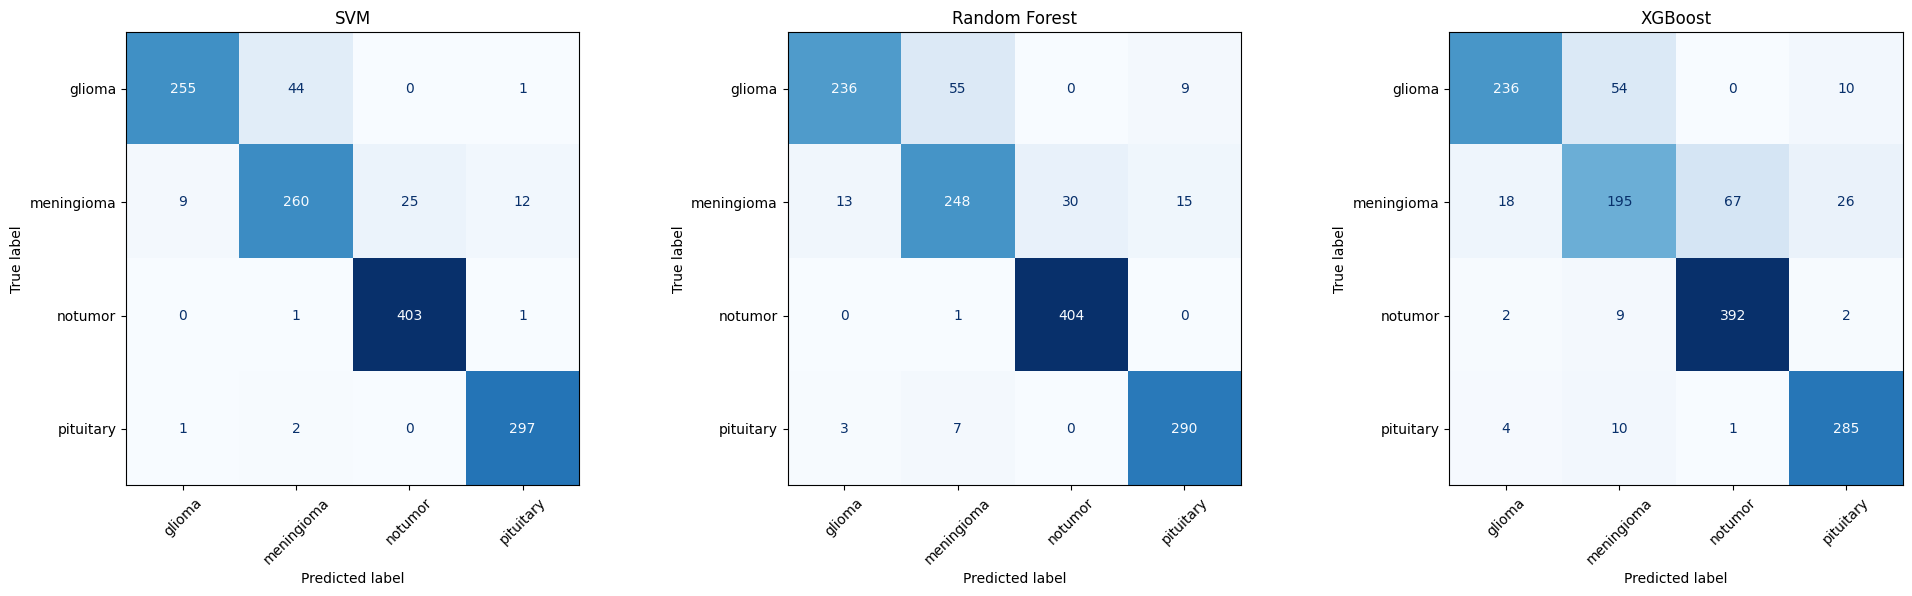

In [53]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

predictions = {
    "SVM": y_pred_svm_test,
    "Random Forest": y_pred_rf_test,
    "XGBoost": y_pred_xgb_test
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (name, predictions_model) in zip(
    axes, predictions.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions_model,
        display_labels=classes,
        cmap="Blues",
        ax=ax,
        xticks_rotation=45,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [54]:
import os
import hashlib

def get_image_hashes(folder):

    hashes = {}

    for root, dirs, files in os.walk(folder):

        for file in files:

            if file.lower().endswith(
                ('.jpg', '.jpeg', '.png')
            ):

                path = os.path.join(root, file)

                with open(path, 'rb') as f:
                    image_hash = hashlib.md5(
                        f.read()
                    ).hexdigest()

                hashes.setdefault(image_hash, []).append(path)

    return hashes


train_path = os.path.join(DATASET_PATH, "Training")
test_path = os.path.join(DATASET_PATH, "Testing")

train_hashes = get_image_hashes(train_path)
test_hashes = get_image_hashes(test_path)

duplicates = set(train_hashes.keys()).intersection(
    set(test_hashes.keys())
)

print("Training unique images:", len(train_hashes))
print("Testing unique images:", len(test_hashes))
print("Exact duplicates across datasets:", len(duplicates))

Training unique images: 5521
Testing unique images: 1284
Exact duplicates across datasets: 79


In [55]:

import os
import hashlib
import numpy as np
from sklearn.model_selection import train_test_split

class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

records_by_hash = {}

for split in ["Training", "Testing"]:

    for category in class_names:

        folder = os.path.join(
            DATASET_PATH, split, category
        )

        for filename in os.listdir(folder):

            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png")
            ):
                continue

            path = os.path.join(folder, filename)

            with open(path, "rb") as f:
                image_hash = hashlib.sha256(
                    f.read()
                ).hexdigest()

            if image_hash not in records_by_hash:
                records_by_hash[image_hash] = {
                    "path": path,
                    "labels": set()
                }

            records_by_hash[image_hash]["labels"].add(
                category
            )


# Identify conflicting labels
conflicts = [
    record for record in records_by_hash.values()
    if len(record["labels"]) > 1
]

print("Conflicting-label images:", len(conflicts))


# Keep only images with consistent labels
clean_records = []

for record in records_by_hash.values():

    if len(record["labels"]) == 1:

        clean_records.append({
            "path": record["path"],
            "label": list(record["labels"])[0]
        })


print("Total unique clean images:", len(clean_records))


# Convert class names into numerical labels
class_to_idx = {
    name: i for i, name in enumerate(class_names)
}

all_paths = np.array([
    record["path"] for record in clean_records
])

all_labels = np.array([
    class_to_idx[record["label"]]
    for record in clean_records
])


# Fresh stratified 80:20 split
indices = np.arange(len(all_paths))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

train_paths = all_paths[train_idx]
test_paths = all_paths[test_idx]

y_train = all_labels[train_idx]
y_test = all_labels[test_idx]


print("\nNEW DATASET SPLIT")
print("Training images:", len(train_paths))
print("Testing images:", len(test_paths))

print("\nTraining class distribution:")

for i, name in enumerate(class_names):
    print(name, ":", np.sum(y_train == i))

print("\nTesting class distribution:")

for i, name in enumerate(class_names):
    print(name, ":", np.sum(y_test == i))


Conflicting-label images: 0
Total unique clean images: 6726

NEW DATASET SPLIT
Training images: 5380
Testing images: 1346

Training class distribution:
glioma : 1296
meningioma : 1308
notumor : 1384
pituitary : 1392

Testing class distribution:
glioma : 324
meningioma : 327
notumor : 347
pituitary : 348


In [56]:
import cv2
import numpy as np
from tqdm import tqdm

def extract_dataset_features(paths):

    features = []

    for path in tqdm(paths):

        # Read image
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        if img is None:
            raise ValueError(f"Could not read image: {path}")

        # Resize to 224 x 224
        img = cv2.resize(img, (224, 224))

        # Extract HOG + GLCM
        feature_vector = extract_features_from_gray(img)

        features.append(feature_vector)

    return np.array(features)


# Extract training features
X_train = extract_dataset_features(train_paths)

# Extract testing features
X_test = extract_dataset_features(test_paths)

print("\nFeature extraction completed!")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

100%|██████████| 1346/1346 [01:37<00:00, 13.79it/s]


Feature extraction completed!
Training features: (5380, 6096)
Testing features: (1346, 6096)
Training labels: (5380,)
Testing labels: (1346,)


In [57]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")

print("Scaled training:", X_train_scaled.shape)
print("Scaled testing:", X_test_scaled.shape)

Scaling completed!
Scaled training: (5380, 6096)
Scaled testing: (1346, 6096)


In [58]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

start_time = time.time()

svm_model = SVC(
    kernel='rbf',
    C=1,
    gamma='scale'
)

svm_model.fit(X_train_scaled, y_train)

svm_train_time = time.time() - start_time

print("SVM training completed!")
print("Training time:", round(svm_train_time, 2), "seconds")

# Predictions
y_pred_svm = svm_model.predict(X_test_scaled)

# Accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Test Accuracy:", svm_accuracy * 100)

SVM training completed!
Training time: 93.09 seconds
SVM Test Accuracy: 93.23922734026746


In [59]:
from sklearn.ensemble import RandomForestClassifier
import time

start_time = time.time()

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_train_time = time.time() - start_time

print("Random Forest training completed!")
print("Training time:", round(rf_train_time, 2), "seconds")

# Predictions
y_pred_rf = rf_model.predict(X_test)

# Accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Test Accuracy:", rf_accuracy * 100)

Random Forest training completed!
Training time: 121.11 seconds
Random Forest Test Accuracy: 91.75334323922733


In [62]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["SVM", "Random Forest"],

    "Accuracy (%)": [
        svm_accuracy * 100,
        rf_accuracy * 100
    ],

    "Training Time (seconds)": [
        svm_train_time,
        rf_train_time
    ]
})

print(results.to_string(index=False))

        Model  Accuracy (%)  Training Time (seconds)
          SVM     93.239227                93.090543
Random Forest     91.753343               121.111793


SVM Classification Report:
              precision    recall  f1-score   support

      glioma       0.98      0.89      0.93       324
  meningioma       0.83      0.91      0.87       327
     notumor       0.98      0.95      0.96       347
   pituitary       0.95      0.98      0.97       348

    accuracy                           0.93      1346
   macro avg       0.93      0.93      0.93      1346
weighted avg       0.94      0.93      0.93      1346



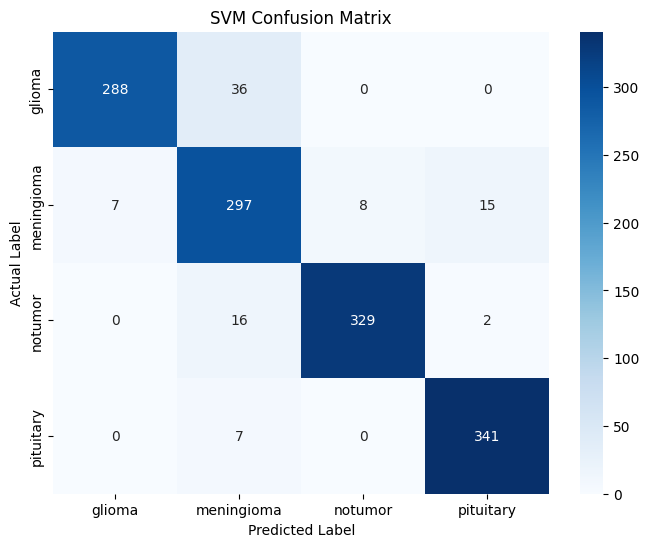

In [63]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("SVM Classification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=class_names
))

cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")
plt.show()

In [64]:
!pip install lime

Test image index: 0
Actual class: glioma
Predicted class: glioma


  0%|          | 0/500 [00:00<?, ?it/s]

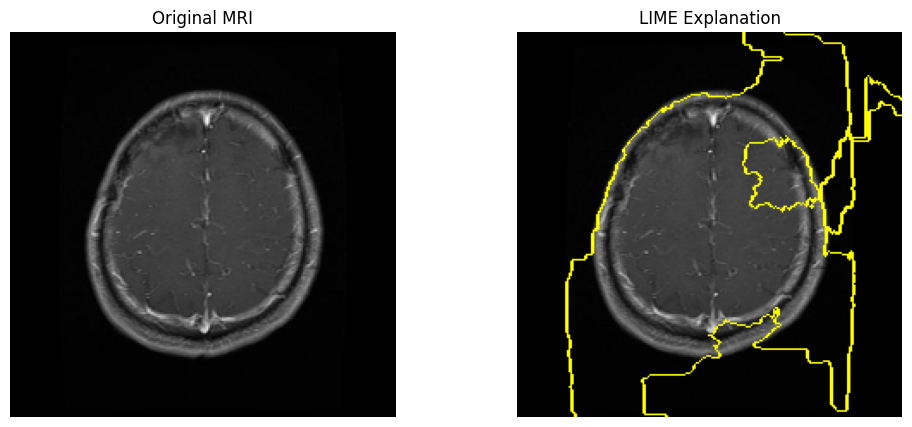

In [65]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from lime import lime_image
from scipy.special import softmax
from skimage.segmentation import mark_boundaries

# 1. Select a correctly classified test image
correct_indices = np.where(y_pred_svm == y_test)[0]
sample_idx = correct_indices[0]

print("Test image index:", sample_idx)

# 2. Load and preprocess the image
img = cv2.imread(test_paths[sample_idx])
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = cv2.resize(img, (224, 224))

# 3. Get the model's predicted class
predicted_label = int(y_pred_svm[sample_idx])

print("Actual class:", class_names[int(y_test[sample_idx])])
print("Predicted class:", class_names[predicted_label])


# 4. Create prediction function for LIME
def lime_predict(images):

    features = []

    for image in images:

        # Convert RGB to grayscale
        gray = cv2.cvtColor(
            image.astype(np.uint8),
            cv2.COLOR_RGB2GRAY
        )

        gray = cv2.resize(gray, (224, 224))

        # Extract HOG + GLCM features
        feature = extract_features_from_gray(gray)

        features.append(feature)

    features = np.array(features)

    # Apply the already-fitted scaler
    features_scaled = scaler.transform(features)

    # Get SVM decision scores
    scores = svm_model.decision_function(features_scaled)

    # Normalize scores for LIME's interface
    return softmax(scores, axis=1)


# 5. Create LIME explainer
explainer = lime_image.LimeImageExplainer()

explanation = explainer.explain_instance(
    img,
    lime_predict,
    labels=(predicted_label,),
    hide_color=0,
    num_samples=500
)

# 6. Display explanation
temp, mask = explanation.get_image_and_mask(
    predicted_label,
    positive_only=False,
    num_features=10,
    hide_rest=False
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(img / 255.0, mask))
plt.title("LIME Explanation")
plt.axis("off")

plt.show()

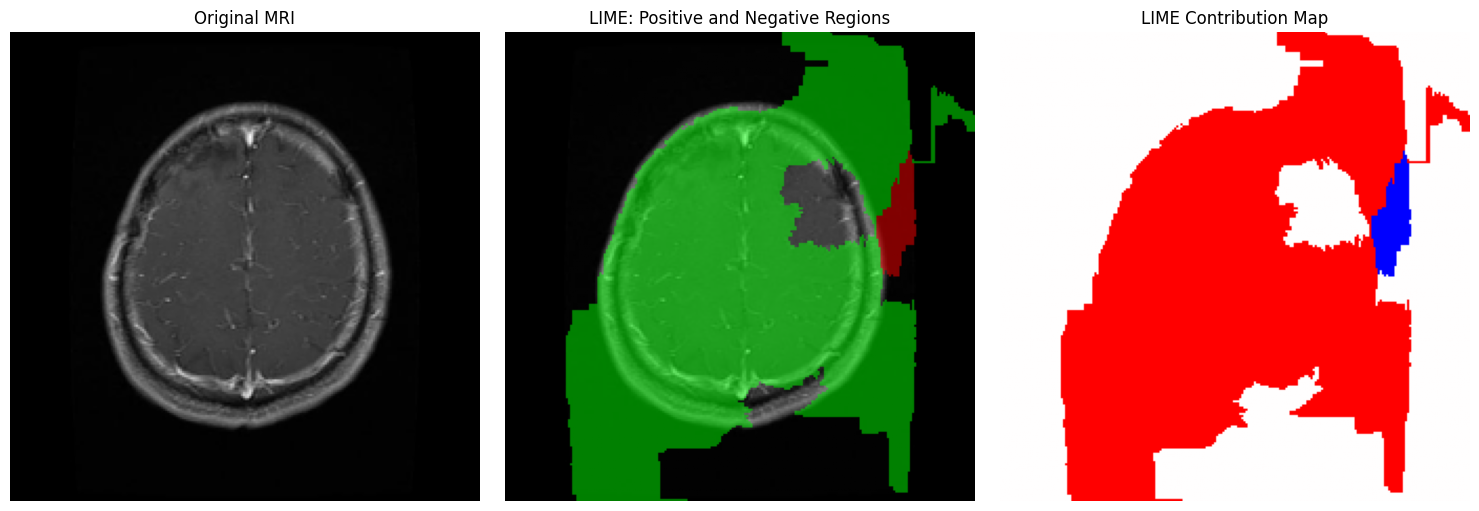

In [66]:
import numpy as np
import matplotlib.pyplot as plt

# Get LIME explanation
temp, mask = explanation.get_image_and_mask(
    predicted_label,
    positive_only=False,
    num_features=10,
    hide_rest=False
)

# Create a copy of the original image
overlay = img.astype(float) / 255.0

# Positive regions: green
overlay[mask == 1] = (
    0.5 * overlay[mask == 1] +
    0.5 * np.array([0, 1, 0])
)

# Negative regions: red
overlay[mask == -1] = (
    0.5 * overlay[mask == -1] +
    0.5 * np.array([1, 0, 0])
)

# Display
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(overlay)
plt.title("LIME: Positive and Negative Regions")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask, cmap="bwr", vmin=-1, vmax=1)
plt.title("LIME Contribution Map")
plt.axis("off")

plt.tight_layout()
plt.show()

Predicted class: glioma


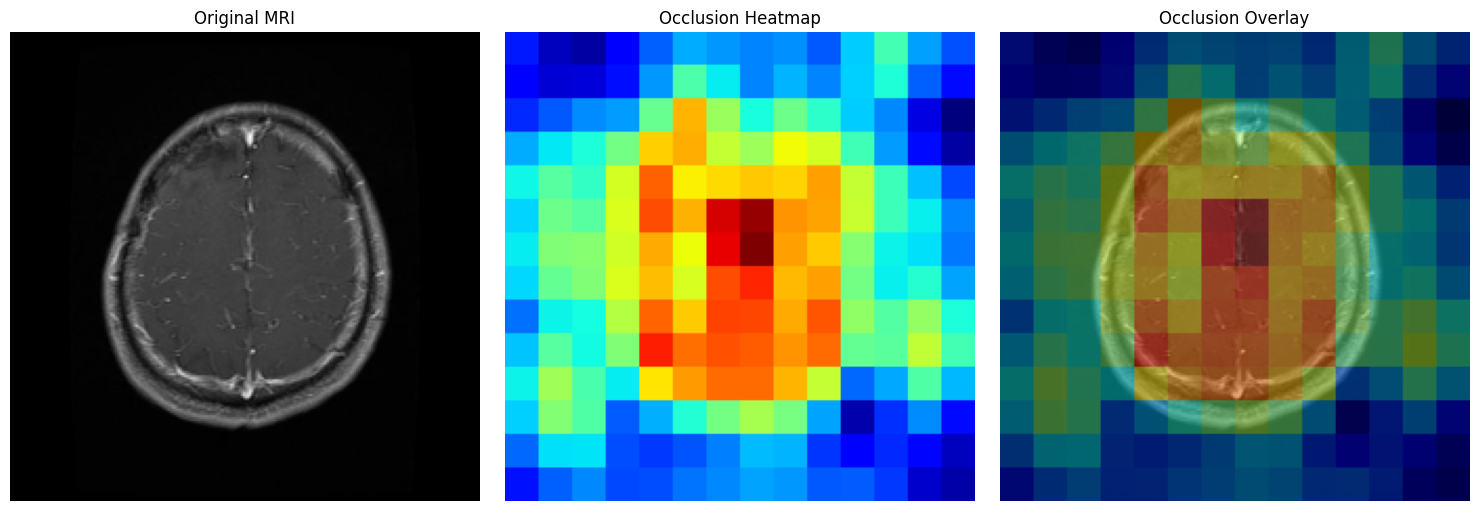

In [67]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Prepare the same MRI image used for LIME
gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
gray_img = cv2.resize(gray_img, (224, 224))

# Get original prediction scores
original_scores = get_prediction_scores(gray_img)

# Class predicted by SVM
predicted_label = int(svm_model.predict(
    scaler.transform(
        np.array([extract_features_from_gray(gray_img)])
    )
)[0])

print("Predicted class:", class_names[predicted_label])

# Parameters
patch_size = 32
stride = 16

heatmap = np.zeros((224, 224), dtype=np.float32)
count_map = np.zeros((224, 224), dtype=np.float32)

# Hide patches one by one
for y in range(0, 224 - patch_size + 1, stride):
    for x in range(0, 224 - patch_size + 1, stride):

        occluded_img = gray_img.copy()

        # Hide the selected patch
        occluded_img[
            y:y + patch_size,
            x:x + patch_size
        ] = 0

        # Get prediction after hiding patch
        new_scores = get_prediction_scores(occluded_img)

        # Change in predicted-class score
        score_change = (
            original_scores[predicted_label]
            - new_scores[predicted_label]
        )

        heatmap[
            y:y + patch_size,
            x:x + patch_size
        ] += score_change

        count_map[
            y:y + patch_size,
            x:x + patch_size
        ] += 1

# Average overlapping patch values
heatmap = heatmap / np.maximum(count_map, 1)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_img, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Occlusion Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gray_img, cmap="gray")
plt.imshow(heatmap, cmap="jet", alpha=0.45)
plt.title("Occlusion Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [68]:
import shap
import numpy as np
import matplotlib.pyplot as plt

# Use 20 clean test samples
# Random Forest was trained on unscaled features
X_shap = X_test[:20]

# Create SHAP explainer
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_array = np.stack(shap_values, axis=-1)
else:
    shap_array = np.asarray(shap_values)

# Ensure shape is (samples, features, classes)
if shap_array.ndim == 3:
    if shap_array.shape[0] == len(class_names) and shap_array.shape[1] == len(X_shap):
        shap_array = np.transpose(shap_array, (1, 2, 0))

print("SHAP array shape:", shap_array.shape)
print("Number of test samples:", len(X_shap))
print("Number of features:", X_shap.shape[1])

SHAP array shape: (20, 6096, 4)
Number of test samples: 20
Number of features: 6096


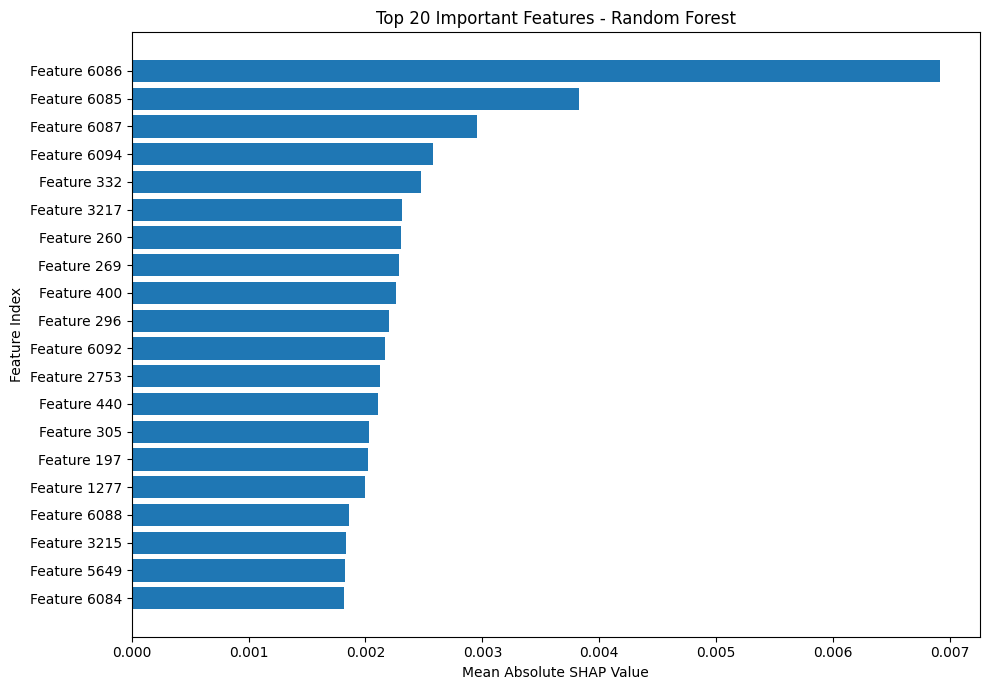

In [69]:
# Average absolute SHAP importance across samples and classes
feature_importance = np.mean(
    np.abs(shap_array),
    axis=(0, 2)
)

# Select top 20 features
top_indices = np.argsort(feature_importance)[-20:]

plt.figure(figsize=(10, 7))

plt.barh(
    [f"Feature {i}" for i in top_indices],
    feature_importance[top_indices]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature Index")
plt.title("Top 20 Important Features - Random Forest")
plt.tight_layout()
plt.show()

Average HOG importance: 0.00010660900783919446
Average GLCM importance: 0.00235063513951874


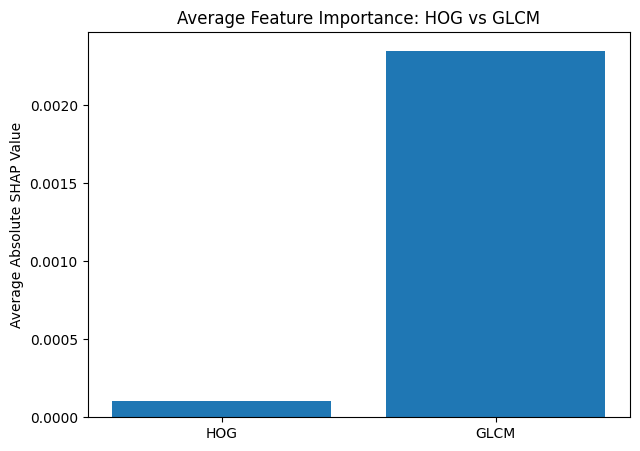

In [70]:
hog_importance = np.mean(feature_importance[:6084])
glcm_importance = np.mean(feature_importance[6084:])

print("Average HOG importance:", hog_importance)
print("Average GLCM importance:", glcm_importance)

plt.figure(figsize=(7, 5))

plt.bar(
    ["HOG", "GLCM"],
    [hog_importance, glcm_importance]
)

plt.ylabel("Average Absolute SHAP Value")
plt.title("Average Feature Importance: HOG vs GLCM")
plt.show()

GLCM Feature 1: 0.00181271
GLCM Feature 2: 0.00382541
GLCM Feature 3: 0.00691070
GLCM Feature 4: 0.00295435
GLCM Feature 5: 0.00185832
GLCM Feature 6: 0.00089046
GLCM Feature 7: 0.00147501
GLCM Feature 8: 0.00134403
GLCM Feature 9: 0.00216308
GLCM Feature 10: 0.00159083
GLCM Feature 11: 0.00257614
GLCM Feature 12: 0.00080657


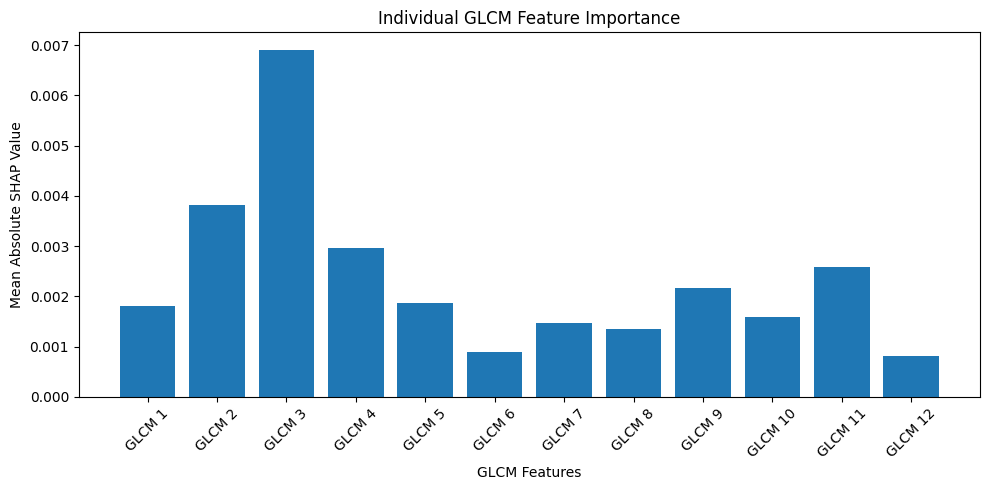

In [71]:
# Get GLCM feature importance
glcm_features = feature_importance[6084:]

# Display importance of all 12 GLCM features
for i, importance in enumerate(glcm_features):
    print(
        f"GLCM Feature {i+1}: {importance:.8f}"
    )

# Plot GLCM feature importance
plt.figure(figsize=(10, 5))

plt.bar(
    [f"GLCM {i+1}" for i in range(12)],
    glcm_features
)

plt.xlabel("GLCM Features")
plt.ylabel("Mean Absolute SHAP Value")
plt.title("Individual GLCM Feature Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [72]:
!pip install joblib

In [73]:
import joblib

model_artifacts = {
    "svm_model": svm_model,
    "scaler": scaler,
    "class_names": class_names,
    "image_size": (224, 224)
}

joblib.dump(
    model_artifacts,
    "/content/brain_tumor_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [74]:
from google.colab import files

files.download("/content/brain_tumor_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [76]:
!pip install -q streamlit pyngrok opencv-python-headless scikit-image joblib

In [77]:
import streamlit
import cv2
import joblib

print("Streamlit:", streamlit.__version__)
print("All imports successful!")

Streamlit: 1.67.0
All imports successful!


In [79]:
import inspect

try:
    print(inspect.getsource(extract_features_from_gray))

except Exception as e:
    print("Could not retrieve function:", e)

def extract_features_from_gray(img):

    hog_features = hog(
        img,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        feature_vector=True
    )

    glcm = graycomatrix(
        img,
        distances=[1, 2],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=256,
        symmetric=True,
        normed=True
    )

    properties = [
        'contrast',
        'dissimilarity',
        'homogeneity',
        'energy',
        'correlation',
        'ASM'
    ]

    glcm_features = []

    for prop in properties:
        values = graycoprops(glcm, prop)
        glcm_features.append(values.mean())
        glcm_features.append(values.std())

    return np.concatenate([
        hog_features,
        glcm_features
    ])



In [80]:

%%writefile app.py

import streamlit as st
import numpy as np
import cv2
import joblib
import matplotlib.pyplot as plt

from skimage.feature import hog, graycomatrix, graycoprops
from scipy.special import softmax

# -----------------------------
# 1. Load trained model
# -----------------------------

artifacts = joblib.load("/content/brain_tumor_model.pkl")

svm_model = artifacts["svm_model"]
scaler = artifacts["scaler"]
class_names = artifacts["class_names"]

# -----------------------------
# 2. Feature extraction
# -----------------------------

def extract_features_from_gray(img):

    hog_features = hog(
        img,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        feature_vector=True
    )

    glcm = graycomatrix(
        img,
        distances=[1, 2],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=256,
        symmetric=True,
        normed=True
    )

    properties = [
        'contrast',
        'dissimilarity',
        'homogeneity',
        'energy',
        'correlation',
        'ASM'
    ]

    glcm_features = []

    for prop in properties:
        values = graycoprops(glcm, prop)
        glcm_features.append(values.mean())
        glcm_features.append(values.std())

    return np.concatenate([
        hog_features,
        glcm_features
    ])

# -----------------------------
# 3. Prediction function
# -----------------------------

def get_prediction_scores(gray_img):

    features = extract_features_from_gray(gray_img)

    features = features.reshape(1, -1)

    features_scaled = scaler.transform(features)

    decision_scores = svm_model.decision_function(
        features_scaled
    )

    return softmax(decision_scores, axis=1)[0]


def predict_image(gray_img):

    features = extract_features_from_gray(gray_img)

    features_scaled = scaler.transform(
        features.reshape(1, -1)
    )

    prediction = int(svm_model.predict(features_scaled)[0])

    scores = get_prediction_scores(gray_img)

    return prediction, scores

# -----------------------------
# 4. Occlusion heatmap
# -----------------------------

def generate_occlusion_heatmap(gray_img, predicted_label):

    original_scores = get_prediction_scores(gray_img)

    patch_size = 32
    stride = 16

    heatmap = np.zeros((224, 224), dtype=np.float32)
    count_map = np.zeros((224, 224), dtype=np.float32)

    for y in range(0, 224 - patch_size + 1, stride):

        for x in range(0, 224 - patch_size + 1, stride):

            occluded_img = gray_img.copy()

            occluded_img[
                y:y + patch_size,
                x:x + patch_size
            ] = 0

            new_scores = get_prediction_scores(occluded_img)

            score_change = (
                original_scores[predicted_label]
                - new_scores[predicted_label]
            )

            heatmap[
                y:y + patch_size,
                x:x + patch_size
            ] += score_change

            count_map[
                y:y + patch_size,
                x:x + patch_size
            ] += 1

    heatmap = heatmap / np.maximum(count_map, 1)

    return heatmap

# -----------------------------
# 5. Streamlit interface
# -----------------------------

st.set_page_config(
    page_title="Brain Tumor Classification",
    page_icon="🧠",
    layout="wide"
)

st.title("🧠 Brain Tumor Classification System")

st.write(
    "MRI classification using traditional machine learning "
    "with HOG and GLCM feature extraction."
)

st.info(
    "Research prototype only. This application is not "
    "clinically validated and must not be used for diagnosis."
)

uploaded_file = st.file_uploader(
    "Upload a brain MRI image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    file_bytes = np.asarray(
        bytearray(uploaded_file.read()),
        dtype=np.uint8
    )

    original_img = cv2.imdecode(
        file_bytes,
        cv2.IMREAD_GRAYSCALE
    )

    if original_img is None:

        st.error("Unable to read this image.")

    else:

        gray_img = cv2.resize(
            original_img,
            (224, 224)
        )

        col1, col2 = st.columns(2)

        with col1:

            st.subheader("Uploaded MRI")
            st.image(
                gray_img,
                clamp=True,
                use_container_width=True
            )

        with st.spinner("Analyzing MRI image..."):

            predicted_label, scores = predict_image(gray_img)

        predicted_class = class_names[predicted_label]

        with col2:

            st.subheader("Prediction Result")

            st.success(
                f"Predicted class: {predicted_class}"
            )

            st.write("Normalized SVM decision scores:")

            for i, class_name in enumerate(class_names):

                st.write(
                    f"{class_name}: {scores[i] * 100:.2f}%"
                )

                st.progress(float(scores[i]))

        st.divider()

        # Occlusion explanation

        st.subheader("Occlusion Sensitivity Heatmap")

        if st.button("Generate Explanation"):

            with st.spinner(
                "Generating heatmap. Please wait..."
            ):

                heatmap = generate_occlusion_heatmap(
                    gray_img,
                    predicted_label
                )

            fig, axes = plt.subplots(1, 2, figsize=(12, 5))

            axes[0].imshow(gray_img, cmap="gray")
            axes[0].set_title("Original MRI")
            axes[0].axis("off")

            axes[1].imshow(gray_img, cmap="gray")
            axes[1].imshow(
                heatmap,
                cmap="jet",
                alpha=0.45
            )
            axes[1].set_title("Occlusion Heatmap")
            axes[1].axis("off")

            plt.tight_layout()

            st.pyplot(fig)

            plt.close(fig)

            st.caption(
                "The heatmap shows model sensitivity to image "
                "patches, not tumor boundaries."
            )


Writing app.py


In [81]:
!streamlit run app.py --server.port 8501 --server.headless true &>/content/streamlit.log &

In [83]:
!pkill -f streamlit

In [84]:
!streamlit run app.py --server.port 8501 --server.headless true &>/content/streamlit.log &

In [85]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501, height=900)

<IPython.core.display.Javascript object>

In [86]:
!cat /content/streamlit.log



2026-11-22 22:15:08.295 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.229.113.92:8501

2026-11-22 22:15:31.847 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c5-3anjjdxeuuyqm-c.us-east1.prod.r.colab.dev, host=m-s-use1c5-3anjjdxeuuyqm.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-22 22:15:33.783 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c5-3anjjdxeuuyqm-c.us-east1.prod.r.colab.dev, host=m-s-use1c5-3anjjdxeuuyqm.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-22 22:15:36.267 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c5-3anjjdxeuuyqm-c.us-east1.prod.r.colab.dev, host=m-s-use1c5-3anjjdxeuuyqm.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-22 22:15:39

In [89]:
!pkill -f "streamlit run app.py" || true

^C


In [90]:
!streamlit run app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.headless true \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --browser.gatherUsageStats false \
    > /content/streamlit.log 2>&1 &

In [91]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501, height=900)

<IPython.core.display.Javascript object>

In [92]:
from google.colab import files

files.download("/content/app.py")
files.download("/content/brain_tumor_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [93]:
import os

files_to_check = [
    "/content/app.py",
    "/content/brain_tumor_model.pkl"
]

for file_path in files_to_check:
    if os.path.exists(file_path):
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"FOUND: {os.path.basename(file_path)}")
        print(f"Size: {size_mb:.2f} MB\n")
    else:
        print(f"MISSING: {os.path.basename(file_path)}\n")

FOUND: app.py
Size: 0.01 MB

FOUND: brain_tumor_model.pkl
Size: 154.25 MB



In [94]:
!pip install -q huggingface_hub


In [96]:
from huggingface_hub import notebook_login

notebook_login()

In [99]:
from huggingface_hub import HfApi

api = HfApi()

api.upload_file(
    path_or_fileobj="/content/brain_tumor_model.pkl",
    path_in_repo="brain_tumor_model.pkl",
    repo_id="Utkarsh566/brain-tumor-classification-model",
    repo_type="model"
)

print("Model uploaded successfully!")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...ent/brain_tumor_model.pkl:   0%|          |  525kB /  162MB            

Validating                    :           |   0%            

Model uploaded successfully!


In [100]:
model_artifacts = joblib.load("/content/brain_tumor_model.pkl")

In [101]:
import joblib
from huggingface_hub import hf_hub_download

MODEL_PATH = hf_hub_download(
    repo_id="Utkarsh566/brain-tumor-classification-model",
    filename="brain_tumor_model.pkl"
)

model_artifacts = joblib.load(MODEL_PATH)

svm_model = model_artifacts["svm_model"]
scaler = model_artifacts["scaler"]
class_names = model_artifacts["class_names"]

brain_tumor_model.pkl: reconstructing file:   0%|          |  0.00B /  162MB            

brain_tumor_model.pkl: downloading bytes:           |  0.00B            

In [102]:
with open("/content/app.py", "r") as f:
    app_code = f.read()

checks = {
    "Hugging Face download": "hf_hub_download" in app_code,
    "Model repository configured": "brain-tumor-classification-model" in app_code,
    "SVM model loading": '["svm_model"]' in app_code,
    "Scaler loading": '["scaler"]' in app_code,
    "Class names loading": '["class_names"]' in app_code
}

for name, passed in checks.items():
    print(("PASS" if passed else "CHECK") + ":", name)

CHECK: Hugging Face download
CHECK: Model repository configured
PASS: SVM model loading
PASS: Scaler loading
PASS: Class names loading


In [103]:
with open("/content/app.py", "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    if any(word in line for word in [
        "joblib.load",
        "model_artifacts",
        "MODEL_PATH",
        "svm_model"
    ]):
        print(f"Line {i+1}: {line.rstrip()}")

Line 15: artifacts = joblib.load("/content/brain_tumor_model.pkl")
Line 17: svm_model = artifacts["svm_model"]
Line 77:     decision_scores = svm_model.decision_function(
Line 92:     prediction = int(svm_model.predict(features_scaled)[0])


In [104]:
from huggingface_hub import hf_hub_download

new_model_code = '''
MODEL_PATH = hf_hub_download(
    repo_id="Utkarsh566/brain-tumor-classification-model",
    filename="brain_tumor_model.pkl"
)

artifacts = joblib.load(MODEL_PATH)

svm_model = artifacts["svm_model"]
scaler = artifacts["scaler"]
class_names = artifacts["class_names"]
'''

with open("/content/app.py", "r") as f:
    lines = f.readlines()

# Replace the old model-loading section (lines 15 onward)
# Keep the rest of the application unchanged.
start = next(
    i for i, line in enumerate(lines)
    if 'artifacts = joblib.load' in line
)

end = next(
    i for i in range(start, len(lines))
    if 'class_names = artifacts["class_names"]' in lines[i]
) if any('class_names = artifacts["class_names"]' in line for line in lines[start:]) else start

if end == start:
    print("STOP: Could not safely identify the complete old model-loading section.")
else:
    updated_lines = (
        lines[:start] +
        [new_model_code + "\n"] +
        lines[end+1:]
    )

    with open("/content/app.py", "w") as f:
        f.writelines(updated_lines)

    print("Model-loading section updated!")

Model-loading section updated!


In [105]:
with open("/content/app.py", "r") as f:
    app_code = f.read()

print("Hugging Face download:", "hf_hub_download" in app_code)
print("Repository configured:", "YOUR_USERNAME" not in app_code)
print("Old Colab path removed:", "/content/brain_tumor_model.pkl" not in app_code)
print("SVM loading:", 'artifacts["svm_model"]' in app_code)
print("Scaler loading:", 'artifacts["scaler"]' in app_code)

Hugging Face download: True
Repository configured: True
Old Colab path removed: True
SVM loading: True
Scaler loading: True


In [106]:
%%writefile /content/requirements.txt

streamlit
numpy
opencv-python-headless
scikit-image
scikit-learn
joblib
matplotlib
scipy
huggingface_hub
Pillow

Writing /content/requirements.txt


In [107]:
with open("/content/requirements.txt", "r") as f:
    print(f.read())


streamlit
numpy
opencv-python-headless
scikit-image
scikit-learn
joblib
matplotlib
scipy
huggingface_hub
Pillow



In [108]:
%%writefile /content/.gitignore

__pycache__/
*.pyc
.ipynb_checkpoints/
.env
venv/
.venv/
.DS_Store

# Do not upload the MRI dataset
Training/
Testing/
dataset/

# Local model artifact (hosted on Hugging Face)
brain_tumor_model.pkl

Writing /content/.gitignore


In [109]:

%%writefile /content/README.md

# Brain Tumor Classification using Computer Vision and Traditional Machine Learning

An MRI-based brain tumor classification system built using handcrafted feature extraction and traditional machine learning algorithms, with an interactive Streamlit application and Explainable AI techniques.

<p align="center">
  <strong>HOG + GLCM | SVM | Random Forest | SHAP | LIME | Occlusion Sensitivity | Streamlit</strong>
</p>

---

## 1. Project Overview

Brain tumors are abnormal growths of cells in or around the brain. Early examination and accurate interpretation of brain MRI scans are important parts of clinical assessment.

This project explores the classification of brain MRI images into four categories using Computer Vision and Traditional Machine Learning.

Unlike CNN-based approaches, this implementation uses handcrafted image features extracted using:

- Histogram of Oriented Gradients (HOG)
- Gray-Level Co-occurrence Matrix (GLCM)

The extracted features are used to train and evaluate two machine learning classifiers:

- Support Vector Machine (SVM)
- Random Forest

The project also explores Explainable AI methods to investigate which features and image regions influence model predictions.

An interactive Streamlit application allows users to upload MRI images and view classification results and an occlusion-based explanation.

### Classification Categories

1. Glioma
2. Meningioma
3. Pituitary Tumor
4. No Tumor

---

## 2. Medical Background

A brain tumor is an abnormal growth of cells in or around the brain. Brain tumors can be classified in different ways, including by their origin, biological behaviour and anatomical location.

MRI is commonly used to examine brain structures and abnormalities because it provides detailed soft-tissue images.

### A. Glioma

Gliomas are tumors that arise from glial cells, which support and protect nerve cells in the central nervous system.

Their appearance on MRI can vary depending on the tumor type, grade and other characteristics.

### B. Meningioma

Meningiomas originate from the meninges, the protective membranes surrounding the brain and spinal cord.

They are often located outside the brain tissue itself and can have different imaging appearances depending on their size and location.

### C. Pituitary Tumor

Pituitary tumors develop in or around the pituitary gland, a small gland located at the base of the brain.

Some pituitary tumors can affect hormone production or surrounding structures.

MRI is useful for examining the pituitary region and identifying structural abnormalities.

### D. No Tumor

This category represents MRI images labelled as not containing any of the three target tumor categories in the dataset.

A model prediction of No Tumor does not establish that a patient is medically healthy.

### Category Comparison

| Category | Origin / Location | Description |
|---|---|---|
| Glioma | Glial cells | Tumors arising from glial cells |
| Meningioma | Meninges | Tumors arising from protective brain membranes |
| Pituitary | Pituitary gland | Tumors developing in or around the pituitary gland |
| No Tumor | No target tumor label | Images labelled as not containing the target tumor categories |

---

## 3. Dataset

The dataset contains brain MRI images belonging to four classes.

### Dataset Statistics

| Parameter | Value |
|---|---:|
| Total unique images | 6,726 |
| Training images | 5,380 |
| Testing images | 1,346 |
| Training split | 80% |
| Testing split | 20% |
| Random state | 42 |
| Image dimensions | 224 × 224 |
| Number of classes | 4 |

### Test Set Distribution

| Class | Images |
|---|---:|
| Glioma | 324 |
| Meningioma | 327 |
| No Tumor | 347 |
| Pituitary | 348 |
| **Total** | **1,346** |

### Duplicate Removal and Data Splitting

The original dataset contained separate Training and Testing folders.

Exact duplicate images across these folders were identified using SHA-256 hashing.

A total of 79 exact duplicate images were removed.

The resulting unique dataset was divided using a stratified 80:20 image-level split with random state 42.

Stratification helps preserve class proportions across training and testing sets.

**Evaluation limitation:** This is an image-level split, not a patient-level split. Patient-level generalization has not been established. Multiple images from the same patient may still exist across the two subsets.

The original MRI dataset is not included in this repository.

---

## 4. Image Preprocessing

Each MRI image passes through the following preprocessing steps:

1. Image loading
2. Grayscale conversion
3. Resizing to 224 × 224
4. HOG feature extraction
5. GLCM feature extraction
6. Feature concatenation
7. StandardScaler transformation
8. Machine learning classification

Grayscale conversion provides intensity information for texture analysis and simplifies the feature extraction pipeline.

Resizing ensures consistent image dimensions.

StandardScaler is fitted using training data only and then applied to both training and testing features to avoid data leakage.

---

## 5. Feature Extraction

This project combines structural and texture-based information using HOG and GLCM.

### A. Histogram of Oriented Gradients (HOG)

HOG extracts information based on image gradients and edge orientations.

It divides the image into small cells, calculates orientation histograms and combines them into feature descriptors.

These descriptors capture local structural and shape information.

Configuration:

```python
hog(
    img,
    orientations=9,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2),
    feature_vector=True
)
```

Features extracted per image: **6,084**

### B. Gray-Level Co-occurrence Matrix (GLCM)

GLCM captures spatial relationships between grayscale pixel intensities.

It helps describe texture patterns through the frequency of neighbouring intensity combinations.

Configuration:

```python
glcm = graycomatrix(
    img,
    distances=[1, 2],
    angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
    levels=256,
    symmetric=True,
    normed=True
)
```

The following properties are extracted:

- Contrast
- Dissimilarity
- Homogeneity
- Energy
- Correlation
- ASM (Angular Second Moment)

For every property, the mean and standard deviation are calculated across the distance-angle combinations.

Features extracted per image: **12**

### C. Combined Feature Vector

| Feature Type | Number of Features |
|---|---:|
| HOG | 6,084 |
| GLCM | 12 |
| **Total** | **6,096** |

Combining HOG and GLCM allows the classifiers to use both structural and texture-related image information.

---

## 6. Machine Learning Models

Two traditional machine learning algorithms were evaluated.

### A. Support Vector Machine (SVM)

SVM is a supervised learning algorithm that identifies decision boundaries between classes.

The RBF kernel allows the classifier to model nonlinear relationships between extracted features.

The RBF-kernel SVM achieved the best test performance in this experiment.

### B. Random Forest

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.

Each tree learns from sampled training data and considers subsets of features.

Random Forest was used as a comparative classifier and for exploratory SHAP feature analysis.

### Model Comparison

| Model | Test Accuracy | Training Time |
|---|---:|---:|
| SVM (RBF) | **93.24%** | **93.09 seconds** |
| Random Forest | 91.75% | 121.11 seconds |

SVM was selected as the primary model because it achieved higher test accuracy and lower training time in this experiment.

These results apply to this particular dataset and evaluation setup and do not establish universal model superiority.

---

## 7. Classification Report

The following report represents SVM performance on the held-out test set.

```text
              precision    recall   f1-score   support

      glioma       0.98      0.89      0.93       324
  meningioma       0.83      0.91      0.87       327
     notumor       0.98      0.95      0.96       347
   pituitary       0.95      0.98      0.97       348

    accuracy                           0.93      1346
   macro avg       0.93      0.93      0.93      1346
weighted avg       0.94      0.93      0.93      1346
```

### Understanding the Metrics

- **Precision:** How many predictions for a class were correct.
- **Recall:** How many actual images of a class were correctly identified.
- **F1-score:** The harmonic mean of precision and recall.
- **Support:** Number of actual test images belonging to a class.

Meningioma has the lowest precision (0.83), indicating that a noticeable proportion of images predicted as meningioma belong to other classes.

Glioma recall is 0.89, meaning some actual glioma images were classified as other categories.

These class-level results highlight why accuracy alone is not sufficient for evaluating medical image classification systems.

---

## 8. Explainable AI

Three explainability approaches were explored.

### A. SHAP

SHAP stands for SHapley Additive exPlanations.

It uses Shapley-value-based feature attribution to explain how features contribute to model predictions.

In this project, SHAP was used with the Random Forest model to explore feature importance.

Exploratory results from 20 test samples:

| Feature Group | Average Per-Feature Importance |
|---|---:|
| HOG | 0.000106609 |
| GLCM | 0.002350635 |

GLCM showed higher average importance per individual feature in this exploratory analysis.

However, HOG contains 6,084 features while GLCM contains only 12. Per-feature importance should not be confused with total feature-group importance.

These results are exploratory and based on a small sample.

### B. LIME

LIME stands for Local Interpretable Model-agnostic Explanations.

It explains individual predictions by examining how model outputs change when parts of an input are perturbed.

In this project, LIME was used to visualize image regions that influenced a selected prediction.

The highlighted regions indicate model-influential areas, not tumor segmentation.

### C. Occlusion Sensitivity

Occlusion Sensitivity investigates how predictions change when selected image regions are covered or replaced.

Implementation configuration:

- Patch size: 32 × 32
- Stride: 16
- Overlapping patch scores are averaged.

The resulting heatmap highlights regions where occlusion changes the model's output.

This technique provides insight into the image regions influencing the prediction.

It does not generate a tumor mask or prove that the model focuses on medically meaningful tumor tissue.

---

## 9. Application

The project includes a Streamlit application.

### Features

- MRI image upload
- Image preview
- Four-class classification
- Normalized SVM decision score visualization
- Occlusion Sensitivity heatmap

The application uses the trained SVM model and StandardScaler stored in a Joblib artifact hosted on Hugging Face Hub.

The displayed normalized decision scores are obtained by applying softmax to SVM decision values. They are **not calibrated probabilities**.

---

## 10. Project Architecture

```mermaid
flowchart TD
    A["Brain MRI Dataset"] --> B["Duplicate Removal"]
    B --> C["Stratified Image-Level Split"]
    C --> D["Image Preprocessing"]
    D --> E["Grayscale + Resize 224x224"]
    E --> F["HOG Feature Extraction"]
    E --> G["GLCM Feature Extraction"]
    F --> H["Feature Concatenation"]
    G --> H
    H --> I["StandardScaler"]
    I --> J["SVM and Random Forest"]
    J --> K["Model Evaluation"]
    J --> L["SHAP and LIME"]
    J --> M["Occlusion Sensitivity"]
    J --> N["Streamlit Application"]
```

---

## 11. Tech Stack

| Technology | Purpose |
|---|---|
| Python | Core programming |
| OpenCV | Image preprocessing |
| NumPy | Numerical operations |
| Scikit-image | HOG and GLCM extraction |
| Scikit-learn | Feature scaling and ML models |
| SVM | Primary classifier |
| Random Forest | Comparative classifier |
| SHAP | Feature attribution |
| LIME | Local explanations |
| Matplotlib | Visualization |
| Streamlit | Web application |
| Hugging Face Hub | Model hosting |
| Joblib | Model serialization |
| Google Colab | Development environment |

---

## 12. Repository Structure

```text
Brain-Tumor-Classification/
│
├── app.py
├── requirements.txt
├── README.md
├── .gitignore
├── LICENSE
│
├── notebooks/
│   └── Brain_Tumor_Classification.ipynb
│
├── docs/
│   ├── MEDICAL_BACKGROUND.md
│   ├── METHODOLOGY.md
│   ├── MODEL_EVALUATION.md
│   ├── EXPLAINABLE_AI.md
│   └── DEPLOYMENT_GUIDE.md
│
├── assets/
└── screenshots/
```

The trained model is hosted separately on Hugging Face Hub and is downloaded by the application when required.

---

## 13. Installation and Usage

Clone the repository:

```bash
git clone https://github.com/YOUR_USERNAME/Brain-Tumor-Classification.git
cd Brain-Tumor-Classification
```

Install dependencies:

```bash
pip install -r requirements.txt
```

Run Streamlit:

```bash
streamlit run app.py
```

The application downloads the model from Hugging Face Hub when it starts.

---

## 14. Deployment

The application can be deployed using Streamlit Community Cloud.

General workflow:

1. Push the project repository to GitHub.
2. Open Streamlit Community Cloud.
3. Connect your GitHub account.
4. Select the Brain-Tumor-Classification repository.
5. Select `app.py` as the main application file.
6. Deploy the application.

The model is hosted separately on Hugging Face Hub, so it does not need to be committed to GitHub.

---

## 15. Limitations

This project is an experimental machine learning prototype.

Important limitations:

- The dataset was divided using an image-level split, not a patient-level split.
- Patient-level generalization has not been established.
- External dataset validation has not been performed.
- The model has not undergone clinical validation.
- The model does not perform tumor segmentation.
- The model does not classify tumor grade or stage.
- Normalized decision scores are not calibrated medical probabilities.
- MRI scanners, image quality and acquisition protocols may affect performance.
- Explainability visualizations do not establish clinical reasoning.

---

## 16. Future Improvements

Potential future improvements include:

- Patient-level data splitting.
- External dataset validation.
- Hyperparameter optimization.
- Prediction score calibration.
- More extensive explainability analysis.
- Evaluation by medical imaging professionals.
- Comparison with CNN-based feature extraction approaches.

---

## 17. Disclaimer

This project is developed for educational and research purposes only.

It is not a clinically validated diagnostic system and must not be used for medical diagnosis, treatment decisions or clinical assessment.

All predictions and visual explanations are experimental outputs from a machine learning model.

A qualified medical professional must interpret MRI scans and make clinical decisions.

---

## 18. Acknowledgements

This project was developed as a hands-on exploration of Computer Vision, feature engineering, traditional machine learning, Explainable AI and application deployment.

Special emphasis was placed on understanding the complete pipeline, from MRI preprocessing and handcrafted feature extraction to classification, evaluation and model interpretation.


Writing /content/README.md


In [110]:
import os

path = "/content/README.md"

print("README exists:", os.path.exists(path))
print("README size:", round(os.path.getsize(path) / 1024, 2), "KB")

README exists: True
README size: 15.12 KB


In [111]:
import os

folders = [
    "/content/notebooks",
    "/content/docs",
    "/content/assets",
    "/content/screenshots"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)
    print("Created:", folder)

Created: /content/notebooks
Created: /content/docs
Created: /content/assets
Created: /content/screenshots


In [112]:

import os

docs = {

"MEDICAL_BACKGROUND.md": r"""
# Medical Background

## 1. What is a Brain Tumor?

A brain tumor is an abnormal growth of cells in or around the brain. Brain tumors vary in their origin, biological behaviour, location and imaging characteristics.

MRI (Magnetic Resonance Imaging) is commonly used to examine brain structures because it provides detailed soft-tissue images.

This project explores image classification using MRI images. It is not intended to replace radiological interpretation or clinical diagnosis.

## 2. Classification Categories

### Glioma

Gliomas originate from glial cells, which support and protect neurons in the central nervous system.

Their MRI appearance varies according to tumor subtype, grade and other characteristics. Imaging interpretation requires clinical expertise and may involve additional diagnostic investigations.

### Meningioma

Meningiomas originate from the meninges, the protective membranes surrounding the brain and spinal cord.

They are commonly located outside the brain tissue itself. Their imaging characteristics vary depending on their size, location and biological behaviour.

### Pituitary Tumor

Pituitary tumors develop in or around the pituitary gland, situated at the base of the brain.

Some may affect hormone production or nearby structures. MRI helps examine the pituitary region and identify structural abnormalities.

### No Tumor

This dataset category represents images labelled as not containing one of the three target tumor categories.

A prediction of No Tumor does not establish that a person is medically healthy.

## 3. Comparison

| Category | Origin / Location | General Description |
|---|---|---|
| Glioma | Glial cells | Tumors arising from glial cells |
| Meningioma | Meninges | Tumors arising from protective membranes |
| Pituitary | Pituitary gland | Tumors in or around the pituitary gland |
| No Tumor | No target tumor label | Images without the target tumor labels |

## 4. Role of MRI

MRI provides anatomical and soft-tissue information that can assist clinicians in examining intracranial abnormalities.

However, image classification alone cannot establish a medical diagnosis. Clinical history, radiological interpretation and additional investigations may be required.

## 5. Medical Disclaimer

This project is an experimental educational machine learning prototype. It is not clinically validated and must not be used for diagnosis or treatment decisions.
""",

"METHODOLOGY.md": r"""
# Project Methodology

## 1. Overview

The project uses handcrafted Computer Vision features and traditional Machine Learning to classify MRI images into four categories.

The pipeline:

1. Dataset preparation
2. Exact duplicate removal
3. Stratified image-level splitting
4. Grayscale conversion
5. Image resizing
6. HOG extraction
7. GLCM extraction
8. Feature concatenation
9. StandardScaler transformation
10. SVM and Random Forest training
11. Evaluation and explainability

## 2. Dataset Preparation

- Unique images: 6,726
- Training images: 5,380
- Testing images: 1,346
- Split: 80:20
- Random state: 42
- Exact duplicates removed: 79

SHA-256 hashing was used to identify exact duplicate images across the original Training and Testing folders.

The resulting dataset was divided using stratified image-level splitting.

This was not a patient-level split. Patient-level generalization has not been established.

## 3. Preprocessing

Images were converted to grayscale and resized to 224 × 224 pixels.

Consistent dimensions are required for the configured HOG extraction pipeline.

StandardScaler was fitted using training features only. The fitted scaler was subsequently used to transform training and testing features.

## 4. HOG Feature Extraction

Histogram of Oriented Gradients captures local gradient and edge orientation information.

Configuration:

```python
hog(
    img,
    orientations=9,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2),
    feature_vector=True
)
```

Features per image: 6,084.

## 5. GLCM Feature Extraction

Gray-Level Co-occurrence Matrix captures spatial relationships between grayscale intensity values.

Configuration:

```python
graycomatrix(
    img,
    distances=[1, 2],
    angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
    levels=256,
    symmetric=True,
    normed=True
)
```

Properties:

- Contrast
- Dissimilarity
- Homogeneity
- Energy
- Correlation
- ASM

The mean and standard deviation of each property were calculated across the distance-angle combinations.

Features per image: 12.

## 6. Feature Combination

| Feature Type | Count |
|---|---:|
| HOG | 6,084 |
| GLCM | 12 |
| Total | 6,096 |

Both feature groups were concatenated into a single feature vector.

## 7. Classification

Two models were evaluated:

- RBF-kernel Support Vector Machine
- Random Forest

SVM was selected as the primary model because it achieved higher test accuracy and lower training time in this experiment.

## 8. Inference

The deployed application:

1. Accepts an MRI image.
2. Converts it to grayscale.
3. Resizes it to 224 × 224.
4. Extracts the same 6,096 features.
5. Applies the saved StandardScaler.
6. Predicts using the saved SVM model.
7. Displays the predicted class and normalized decision scores.

The deployed application retrieves the model artifact from Hugging Face Hub.
""",

"MODEL_EVALUATION.md": r"""
# Model Evaluation

## 1. Dataset Split

| Split | Images |
|---|---:|
| Training | 5,380 |
| Testing | 1,346 |
| Total | 6,726 |

The split was stratified and performed at image level using random state 42.

## 2. Model Comparison

| Model | Test Accuracy | Training Time |
|---|---:|---:|
| SVM (RBF) | 93.24% | 93.09 seconds |
| Random Forest | 91.75% | 121.11 seconds |

SVM achieved the higher test accuracy and shorter training time in this experiment.

## 3. SVM Classification Report

```text
              precision    recall   f1-score   support

      glioma       0.98      0.89      0.93       324
  meningioma       0.83      0.91      0.87       327
     notumor       0.98      0.95      0.96       347
   pituitary       0.95      0.98      0.97       348

    accuracy                           0.93      1346
   macro avg       0.93      0.93      0.93      1346
weighted avg       0.94      0.93      0.93      1346
```

## 4. Metric Definitions

- Precision: Fraction of predictions for a class that were correct.
- Recall: Fraction of actual samples of a class that were correctly identified.
- F1-score: Harmonic mean of precision and recall.
- Support: Number of actual test samples in a class.

## 5. Observations

Meningioma has the lowest precision at 0.83.

Glioma recall is 0.89, indicating that some actual glioma images were classified as other categories.

These results show why per-class evaluation is important instead of relying exclusively on overall accuracy.

## 6. Limitations

- Image-level rather than patient-level split.
- No external dataset validation.
- No clinical validation.
- No tumor segmentation or grading.
- Potential dataset-specific patterns and image acquisition differences.

The reported results describe this experiment only. They do not establish clinical performance or patient-level generalization.
""",

"EXPLAINABLE_AI.md": r"""
# Explainable AI

## Overview

This project explores three approaches to understanding model behaviour:

1. SHAP
2. LIME
3. Occlusion Sensitivity

These techniques provide different perspectives on model predictions. Their outputs should not be interpreted as clinical evidence.

## 1. SHAP

SHAP stands for SHapley Additive exPlanations.

It uses Shapley-value-based feature attribution to estimate how individual features contribute to model predictions.

In this project, SHAP was explored using the Random Forest model.

Exploratory results from 20 test samples:

| Feature Group | Average Per-Feature Importance |
|---|---:|
| HOG | 0.000106609 |
| GLCM | 0.002350635 |

GLCM has higher average importance per feature in this exploratory analysis.

However, HOG has 6,084 features, whereas GLCM has only 12. Per-feature importance and aggregate group importance are different measurements.

These results are exploratory and based on a limited sample.

## 2. LIME

LIME stands for Local Interpretable Model-agnostic Explanations.

It approximates model behaviour around an individual prediction by perturbing the input and observing prediction changes.

For image explanations, LIME can use superpixels to identify regions that influence a prediction.

The highlighted areas represent model-influential regions. They are not tumor segmentation masks.

## 3. Occlusion Sensitivity

Occlusion Sensitivity examines how a model's prediction changes when image regions are covered or replaced.

Implementation configuration:

- Patch size: 32 × 32
- Stride: 16
- Overlapping patch scores are averaged.

The resulting heatmap represents changes in model output caused by occluding image regions.

It helps investigate which regions influence predictions.

It does not identify tumor boundaries or establish that the model is focusing on medically meaningful tissue.

## 4. Important Limitations

- Explanations are dependent on the trained model.
- Different explanation methods may produce different results.
- Feature attribution does not establish causality.
- Heatmaps are not medical segmentation.
- These methods do not establish clinical reliability.
""",

"DEPLOYMENT_GUIDE.md": r"""
# Deployment Guide

## 1. Architecture

The project separates application hosting from model hosting.

- GitHub: Application source code and documentation.
- Hugging Face Hub: Trained Joblib model artifact.
- Streamlit Community Cloud: Web application hosting.

## 2. Hugging Face Model Hosting

The trained model is stored in a Hugging Face model repository.

Expected filename:

`brain_tumor_model.pkl`

The application uses `hf_hub_download` to retrieve the artifact.

Example:

```python
from huggingface_hub import hf_hub_download

MODEL_PATH = hf_hub_download(
    repo_id="YOUR_USERNAME/brain-tumor-classification-model",
    filename="brain_tumor_model.pkl"
)
```

Replace the repository ID with the actual repository.

The model repository must be publicly accessible if the deployed application downloads it without authentication.

## 3. GitHub Repository

The GitHub repository should contain:

- app.py
- requirements.txt
- README.md
- .gitignore
- docs/
- notebooks/
- assets/
- screenshots/

Do not upload the MRI dataset.

Do not commit the 154 MB model artifact to regular Git history. It is hosted separately on Hugging Face.

## 4. Requirements

Install dependencies using:

```bash
pip install -r requirements.txt
```

## 5. Local Execution

Run:

```bash
streamlit run app.py
```

## 6. Streamlit Community Cloud

1. Push the project to GitHub.
2. Open Streamlit Community Cloud.
3. Connect your GitHub account.
4. Select the project repository.
5. Choose `app.py` as the main file.
6. Deploy the application.

## 7. Troubleshooting

### Model download errors

Check:
- Repository ID.
- Model filename.
- Repository visibility.
- Hugging Face availability.

### Missing dependency errors

Check that the missing package is present in requirements.txt.

### Model loading errors

Ensure the application loads the correct Joblib artifact and uses compatible versions of the serialization-related libraries.

### Deployment limitations

The first application startup may take longer because the model needs to be downloaded. Hosting and runtime limits depend on the selected deployment service.
"""
}

docs_path = "/content/docs"
os.makedirs(docs_path, exist_ok=True)

for filename, content in docs.items():
    path = os.path.join(docs_path, filename)
    with open(path, "w", encoding="utf-8") as f:
        f.write(content.strip() + "\n")
    print("Created:", filename)

print("\nAll documentation files created successfully!")


Created: MEDICAL_BACKGROUND.md
Created: METHODOLOGY.md
Created: MODEL_EVALUATION.md
Created: EXPLAINABLE_AI.md
Created: DEPLOYMENT_GUIDE.md

All documentation files created successfully!


In [113]:
import os

for filename in os.listdir("/content/docs"):
    path = os.path.join("/content/docs", filename)
    print(filename, "-", round(os.path.getsize(path) / 1024, 2), "KB")

EXPLAINABLE_AI.md - 2.11 KB
METHODOLOGY.md - 2.78 KB
DEPLOYMENT_GUIDE.md - 2.06 KB
MEDICAL_BACKGROUND.md - 2.37 KB
MODEL_EVALUATION.md - 1.82 KB
